## Manuscript comparison and large-file inputs
Prepare a row-preserving plotting extract with `9_prepare_plotting_data.py`. Figure dimensions, colours, fonts, bins, cutoffs and ranking logic are retained; only data loading and unique-probe database lookups are optimized. Existing saved figure outputs below are historical, not a validation of the new data: rerun all cells in order.

Clinical stage labels differ from historical numeric phases. Temporal comparisons cover only available dates in the older evidence snapshot. The default review policy excludes confirmed reviews but retains unknowns for continuity; unknowns are not classified as primary. Use a separate output directory/run for sensitivity analyses. The fixed 2020–2025 and 1998 cutoffs remain unchanged for manuscript comparison.


In [1]:
%run /Users/adasme/Documents/codes/chemical_probes_lit/local_plotting_setup.py

Configured local plotting run: /Users/adasme/Documents/codes/chemical_probes_runs/manuscript_1026
Inputs: /Users/adasme/Documents/codes/chemical_probes_runs/manuscript_1026/inputs
Outputs stay separate from manuscript_original.


### HQ probes in OT NER data


* Define list of High Quality probes
* Find OT NEr subset with HQ probes
* Get all data for identified articles
* subset data for probe-target pairs (it has to be the correct target for the probe)
* Obtain triplets
* Improbe/update grounding
* Get grounded triplets

In [2]:
# External paths: set these environment variables before starting Jupyter.
import os
from pathlib import Path

INPUT_DIR = Path(os.environ["PROBES_INPUT_DIR"]).expanduser().resolve()
RUN_DIR = Path(os.environ["PROBES_RUN_DIR"]).expanduser().resolve()
PROBES_FILE = Path(os.environ.get("PROBES_FILE", str(INPUT_DIR / "probesSubset.csv")))
ANALYSIS_FILE = Path(os.environ.get("PROBES_ANALYSIS_FILE", str(RUN_DIR / "results/plotting/plotting_data.tsv.gz")))
CHEMBL_SQLITE = os.environ.get("CHEMBL_SQLITE")
# Manuscript comparison default: exclude confirmed reviews, retain unknowns.
# Set to classified_non_reviews for a separate sensitivity analysis.
REVIEW_POLICY = os.environ.get("PROBES_REVIEW_POLICY", "exclude_reviews")
np_seed = 0
INTERMEDIATE_DIR = RUN_DIR / "intermediate"
RESULTS_DIR = RUN_DIR / "results"
FIGURES_DIR = RUN_DIR / "figures"
TABLES_DIR = RUN_DIR / "tables"
for directory in (RESULTS_DIR, FIGURES_DIR, TABLES_DIR):
    directory.mkdir(parents=True, exist_ok=True)


In [3]:

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib.colors as mcolors
from matplotlib_venn import venn3, venn3_circles
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator # Need FixedLocator for minor ticks

from collections.abc import Iterable # To check for list-like objects
import re
import seaborn as sns
from collections import Counter
import numpy as np
import requests
import time
pd.set_option('display.max_colwidth', 200)
from helpers.tools import ChemblDB, find_preferred_ta, classify_pubmed_articles

pd.options.mode.chained_assignment = None 
np.random.seed(np_seed)  # Reproducible scatter jitter.


In [4]:
#Counting probes in dictionary
from helpers.plotting_data import PROBE_COLUMNS
hqprobes = pd.read_csv(PROBES_FILE, sep="\t", usecols=PROBE_COLUMNS)
#display(hqprobes)
nprobes = hqprobes.INCHI.nunique()
sprobes = hqprobes.assign(SYNOMS=hqprobes['SYNOMS'].str.split(',')).explode('SYNOMS').SYNOMS.nunique() 
print(nprobes, sprobes)


537 3389


In [5]:
display(hqprobes.columns)
hqprobes.PROBE.nunique()

Index(['SETID', 'PROBE', 'INCHI', 'SYNOMS'], dtype='object')

537

Probes in SGC (28): 106
Probes in Open Science (213): 130
Probes in ChemicalProbes Portal (408): 505
------------------------------


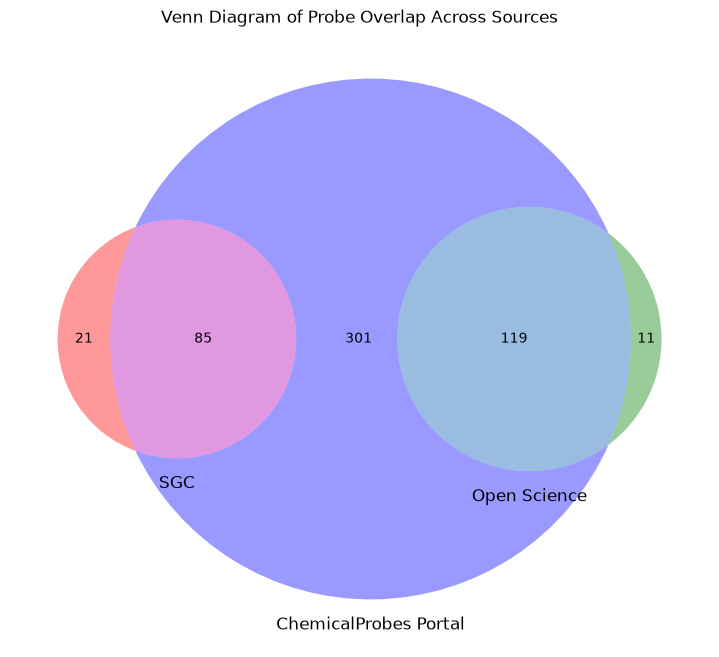

In [6]:
#Plot showing source of probes

subs = hqprobes[['INCHI','SETID']].drop_duplicates()

main_source_1 = 28
main_source_2 = 213
main_source_3 = 408

# Give names to your sources for the plot labels
source_1_name = 'SGC'
source_2_name = 'Open Science'
source_3_name = 'ChemicalProbes Portal'

# --- 3. Create Sets of probeIds for Each Main Source ---
set1 = set()
set2 = set()
set3 = set()

# Iterate through the DataFrame rows
for index, row in subs.iterrows():
    probe_id = row['INCHI']
    sources_entry = row['SETID']

    # Check if the sources_entry is a list/iterable (and not a string)
    if isinstance(sources_entry, Iterable) and not isinstance(sources_entry, str):
        # It's a list (or similar)
        if main_source_1 in sources_entry:
            set1.add(probe_id)
        if main_source_2 in sources_entry:
            set2.add(probe_id)
        if main_source_3 in sources_entry:
            set3.add(probe_id)
    else:
        # It's a single value
        if sources_entry == main_source_1:
            set1.add(probe_id)
        elif sources_entry == main_source_2:
            set2.add(probe_id)
        elif sources_entry == main_source_3:
            set3.add(probe_id)

print(f"Probes in {source_1_name} ({main_source_1}): {len(set1)}")
print(f'Probes in {source_2_name} ({main_source_2}): {len(set2)}')
print(f'Probes in {source_3_name} ({main_source_3}): {len(set3)}')
print("-" * 30)

# --- 4. Generate and Display the Venn Diagram ---
plt.figure(figsize=(10, 8)) # Adjust figure size as needed

# Create the Venn diagram using the sets
# venn3 automatically calculates the sizes of the intersections and unique parts
v = venn3(
    [set1, set2, set3],
    set_labels=(source_1_name, source_2_name, source_3_name)
)

plt.title('Venn Diagram of Probe Overlap Across Sources')
plt.savefig((FIGURES_DIR / 'supp_vd_sources.png'))
plt.show()


In [7]:
#numbers for initial dataset
#numbers1 = pd.read_csv((RESULTS_DIR / 'epmc_ner_results_hq_probes_all_sent.tsv'), sep='\t')
#print(numbers1.pmid.nunique())
#print(numbers1.label.nunique())
#print(numbers1.label_id.nunique())
#print(numbers1.label[numbers1.label.str.startswith('CHEMBL', na=False)].unique()) #Labels include all labels either compoun, target, phenotype

In [8]:
# Step 2 is used only for diagnostic counts, not figure construction.
# Optional counts can be prepared with script 9 --triplets.
import json
manifest_file = Path(str(ANALYSIS_FILE) + ".manifest.json")
plot_manifest = json.loads(manifest_file.read_text()) if manifest_file.exists() else {}
triplet_counts = plot_manifest.get("triplet_summary")


In [ ]:
# Column projection preserves every row and the original row order.
from helpers.clinical_stages import stage_label
from helpers.plotting_data import load_plotting_data, review_selection
from helpers.temporal_analysis import selected_years, add_temporal_years
ner_triplets_ptpairs = load_plotting_data(ANALYSIS_FILE)
if plot_manifest and len(ner_triplets_ptpairs) != plot_manifest["rows"]:
    raise ValueError("Plotting row count differs from the preparation manifest")
print(f"Plotting rows: {len(ner_triplets_ptpairs):,}")
print(f"DataFrame memory: {ner_triplets_ptpairs.memory_usage(deep=True).sum() / 1024**3:.2f} GiB")
print("Article classifications (missing stays unknown):")
print(ner_triplets_ptpairs.articleType.fillna('unknown').value_counts())
print("Date coverage by row (not unique association key):")
print(ner_triplets_ptpairs.datedEvidenceStatus.value_counts(dropna=False))


In [10]:
display(ner_triplets_ptpairs.head(1))

,diseaseId,targetId,datasourceId,datatypeId,score,evidenceCount,pmid,date,section,probeId,...,allpublicationYears,allstudyYears,datedEvidenceStatus,name,therapeuticAreas,drugId,maxClinicalStage,clinicalStageRank,hasClinicalIndication,articleType
0,MONDO_0005059,ENSG00000005339,europepmc,literature,0.959061,498.0,35836809,2022-01-01,other,CHEMBL4097025,...,NaN,NaN,pair_absent,leukemia,MONDO_0005570|MONDO_0045024,NaN,NaN,NaN,False,review


In [11]:
#showing numbers for any probe-target found
if triplet_counts is None:
    print("Step 2 diagnostic counts not prepared. Use script 9 --triplets if needed.")
else:
    print('any probe-target')
    print(triplet_counts['rows'])
    for column, count in triplet_counts['nunique'].items():
        print(column, count)

#showing numbers for the spcific known target for the probe
print('specific probe-target')
print(len(ner_triplets_ptpairs))
for col in ner_triplets_ptpairs:
    print(col, ner_triplets_ptpairs[col].nunique())

Step 2 diagnostic counts not prepared. Use script 9 --triplets if needed.
specific probe-target
1377038
diseaseId 1742
targetId 258
datasourceId 20
datatypeId 8
score 13111
evidenceCount 1609
pmid 31525
date 2681
section 31
probeId 296
sentence 61216
probe 296
inchiKey 296
gene 258
allcurationYears 54
allpublicationYears 1375
allstudyYears 8
datedEvidenceStatus 5
name 1742
therapeuticAreas 415
drugId 424
maxClinicalStage 9
clinicalStageRank 9
hasClinicalIndication 2
articleType 2


In [12]:
print(ner_triplets_ptpairs.pmid.nunique(), ner_triplets_ptpairs.probe.nunique(), ner_triplets_ptpairs.targetId.nunique(), ner_triplets_ptpairs.diseaseId.nunique() )

31525 296 258 1742


In [13]:
ner_triplets_ptpairs.columns

Index(['diseaseId', 'targetId', 'datasourceId', 'datatypeId', 'score',
       'evidenceCount', 'pmid', 'date', 'section', 'probeId', 'sentence',
       'probe', 'inchiKey', 'gene', 'allcurationYears', 'allpublicationYears',
       'allstudyYears', 'datedEvidenceStatus', 'name', 'therapeuticAreas',
       'drugId', 'maxClinicalStage', 'clinicalStageRank',
       'hasClinicalIndication', 'articleType'],
      dtype='object')

#### Max phase of the chemical probe

In [14]:
# Chemical-probe phase is distinct from the target-disease clinical stage.
if not CHEMBL_SQLITE:
    raise ValueError("Set CHEMBL_SQLITE to the selected ChEMBL SQLite database before running this cell")
if not Path(CHEMBL_SQLITE).expanduser().is_file():
    raise FileNotFoundError(f"ChEMBL SQLite database not found: {CHEMBL_SQLITE}")
chembl = ChemblDB(str(Path(CHEMBL_SQLITE).expanduser()))
probe_phases = {
    probe_id: chembl.get_max_phase(probe_id)[0]
    for probe_id in ner_triplets_ptpairs.probeId.dropna().unique()
}
ner_triplets_ptpairs['maxPhase'] = ner_triplets_ptpairs.probeId.map(probe_phases).astype('Int64').replace({np.nan: None})
ner_triplets_ptpairs.groupby('maxPhase')['probeId'].nunique()


maxPhase
1    30
2    40
3    21
4    32
Name: probeId, dtype: int64

In [15]:
# Non drugs probes
drugprobes = ner_triplets_ptpairs[~ner_triplets_ptpairs.maxPhase.isnull()]
nondrugs = ner_triplets_ptpairs[ner_triplets_ptpairs.maxPhase.isnull()]
print(drugprobes.probeId.nunique())
print(nondrugs.probeId.nunique())
print(len(drugprobes[['targetId', 'diseaseId']].drop_duplicates()))
print(len(nondrugs[['targetId', 'diseaseId']].drop_duplicates()))

123
173
7139
3469


In [16]:
#Subset with target-disease pairs having 100 or more articles found (probably to be used to construct a netweor)
subs2 = ner_triplets_ptpairs[ner_triplets_ptpairs.diseaseId.str.startswith(('EFO', 'MONDO', 'HP'), na=False)][['targetId', 'diseaseId', 'probeId', 'pmid']]
#print(subs.head())

# 1. Aggregate data
grouped_data2 = subs2.groupby(['targetId', 'diseaseId']).agg(
    pmid_count=('pmid', pd.Series.nunique),
    probeId_count=('probeId', pd.Series.nunique)
).reset_index()

grouped_data2 = grouped_data2[grouped_data2.pmid_count>=100]
display(grouped_data2.sort_values(by='probeId_count',ascending=False).head())
print(len(grouped_data2))
grouped_data2.to_csv((TABLES_DIR / 'subset_100freq.tsv'), sep='\t', index=False)

,targetId,diseaseId,pmid_count,probeId_count
4047,ENSG00000135679,MONDO_0005070,180,9
5069,ENSG00000143799,MONDO_0004992,657,8
4036,ENSG00000135679,MONDO_0004992,134,7
5068,ENSG00000143799,MONDO_0004989,417,7
5095,ENSG00000143799,MONDO_0005070,741,7


96


#### Sections in articles

,section,counts
0,abbr,172
1,abstract,13191
2,ack_fund,16
3,auth_cont,2
4,case,79
5,comp_int,2
6,concl,2605
7,discuss,18727
8,fig,1227
9,intro,16729


/var/folders/cq/_q5gnhz555511kpb32c3k8940000gp/T/ipykernel_50895/2543996600.py:47: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(df['section'], rotation=45, ha='right')


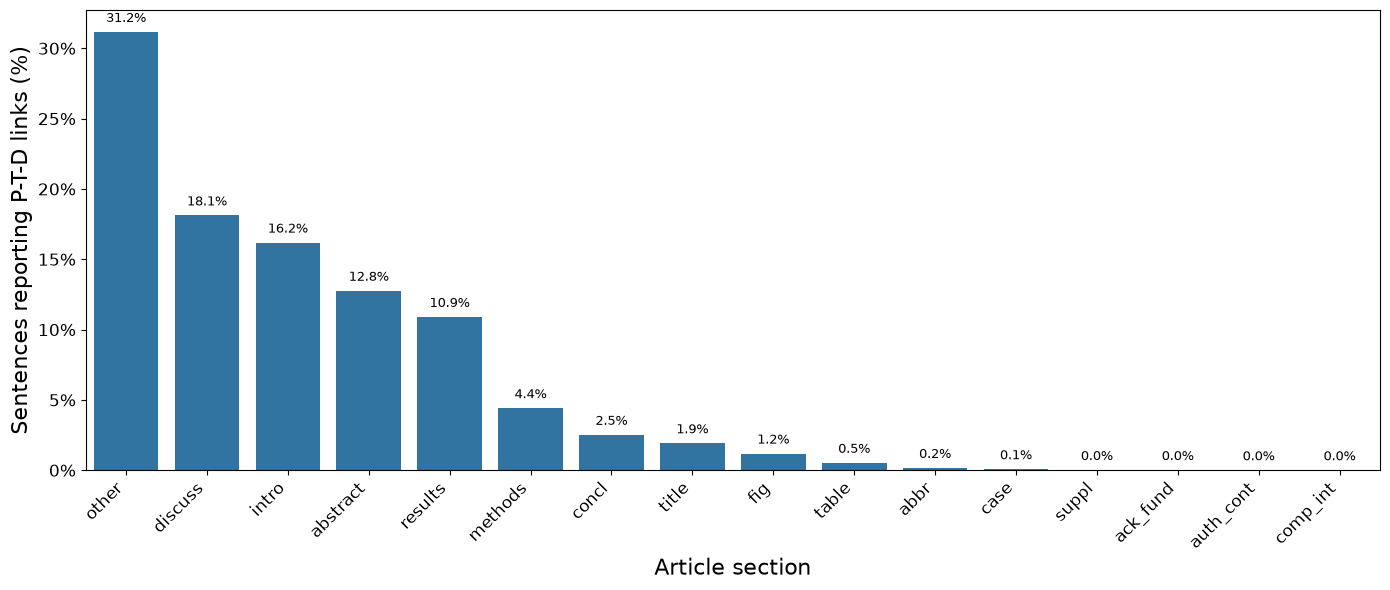

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter # Import the formatter

# 1. Ensure the 'section' column is string type and handle potential missing values
articles = ner_triplets_ptpairs[['diseaseId', 'targetId','pmid','section', 'probeId', 'sentence']].drop_duplicates().dropna(subset=['section']).copy() # Drop rows where section is NaN
articles['section'] = articles['section'].astype(str) 

# 2. Split the 'section' string by comma into a list of strings
#    Use str.strip() within a list comprehension to remove leading/trailing whitespace 
#    from each section name after splitting.
articles['section'] = articles['section'].str.split(',').apply(lambda x: [item.strip() for item in x])

# 3. Explode the DataFrame based on the 'section' list
#    This creates a new row for each item in the list in the 'section' column,
#    duplicating the other column values for that original row.
articles_exploded = articles.explode('section')

secs = articles_exploded.drop_duplicates().groupby('section')['sentence'].count().reset_index(name='counts')
display(secs)
df = secs.sort_values('counts', ascending=False)


# --- New: Calculate percentages ---
total_counts = df['counts'].sum()
df['percentage'] = (df['counts'] / total_counts) * 100

# --- Plotting Code ---
plt.figure(figsize=(14, 6))

# --- Modified: Use 'percentage' for the y-axis ---
ax = sns.barplot(x='section', y='percentage', data=df)

# Rotate x-axis labels
ax.tick_params(axis='x', rotation=45)

# --- Modified: Format Y-axis to show percentages ---
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y:.0f}%'))

# --- Modified: Set Y-axis label to indicate percentage ---
ax.set_ylabel("Sentences reporting P-T-D links (%)", fontsize=16)
ax.set_xlabel("Article section", fontsize=16)

# This part needs to be adjusted based on the actual sections in your data
# For the sample data, we'll get the labels from the DataFrame
ax.set_xticklabels(df['section'], rotation=45, ha='right')


# Increase font size for tick labels
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# --- Modified: Add annotations with percentage values ---
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center',
                va='bottom',
                xytext=(0, 5),
                textcoords='offset points',
                fontsize=9)

# Adjust layout
plt.tight_layout() 

plt.savefig((FIGURES_DIR / 'sections.png'), dpi=400)
# Display the plot
plt.show()

In [18]:
# Examples with sentences found in the "Other" category of the article sections
articles_exploded[articles_exploded.section == 'other'][['pmid','sentence']].head(10)

,pmid,sentence
0,35836809,"The structurally similar GNE-781 displays effective suppression of both CBP (IC50 = 0.94 nM) and p300 (IC50 = 1.2 nM), and strong efficacy in repressing the MYC oncogene (EC50 = 6.6 nM) in leukaem..."
2,35402805,"Indeed, in 2015, the selective CBP/P300 inhibitor I-CBP112 has been reported to inhibit MLL-AF9 leukemia in vitro and in vivo.52 In 2017, another potent and selective inhibitor, A-485, that showed..."
3,35836809,"In myelodysplastic syndrome-derived acute myeloid leukemia cells, CBP/p300 promote the expression of genes important for protein synthesis, and the CBP/p300 HAT inhibitor A-485 and the CBP/p300 br..."
71,39407454,"A-485 (Figure 10) was reported as a potent, selective and drug-like catalytic inhibitor of CBP/p300 that competes with acetyl coenzyme A. A-485 selectively inhibits the proliferation of hematologi..."
72,36831561,"In this review, we focus on summarizing several representative CREBBP/EP300 BRD inhibitors (CCS1477, CPI-637, and GNE272, etc.)and HAT inhibitors (A485, A-241, and C646, etc.)and their functions i..."
155,36661464,"Early preclinical and clinical work in TBI suggests that SUR1-TRPM4 inhibition, via glibenclamide (glyburide), may reduce both edema and hematoma progression and improve outcome; however, effects ..."
212,38607041,"There are other FGFR2 inhibitors such as pemigatinib [117] and infigratinib [118,119] which have been tested in cholangiocarcinoma but not in pancreatic cancer."
235,32392832,"Moreover, BGJ-398, a potent and selective inhibitor of FGFR1–4, completely suppressed tumor growth in a PDX model derived from an SDH-deficient GIST [26]."
236,32392832,"Similarly, Li et al. have confirmed that FGF2 rescues the effect of KIT inhibition and reduces the sensitivity of imatinib in GIST cells, and conversely, the antiproliferative activity of imatinib..."
244,31666694,"Weused BGJ-398, a potent and selective inhibitor of FGFR1-4 in clinicaldevelopment25, and sunitinib,a drug approved for GIST with potent activity against unmutated KIT26."


#### Getting table with triplets (should be adapted to data)

In [19]:
grouped_df = ner_triplets_ptpairs.groupby(['probe', 'targetId']).agg({
    'diseaseId': lambda x: ', '.join([f'{item}[{count}]' for item, count in Counter(x).items()]),
    'pmid': 'nunique'
}).sort_values(by=['pmid']).reset_index()

# Rename aggregated columns
#grouped_df.columns = ['PROBE', 'GENE', 'ALL_DISEASES', 'ARTICLES']
grouped_df = grouped_df.rename(columns={'pmid':'articles'})
display(grouped_df)

,probe,targetId,diseaseId,articles
0,MSC-4381,ENSG00000141526,"MONDO_0005070[18], MONDO_0005061[12]",1
1,BI 99179,ENSG00000169710,"MONDO_0008315[8], Orphanet_1331[8], MONDO_0005159[8]",1
2,DYR684,ENSG00000157540,"MONDO_0005070[9], MONDO_0007256[3]",1
3,AZ3246,ENSG00000104814,MONDO_0004992[2],1
4,AZ6102,ENSG00000173273,MONDO_0004992[10],1
...,...,...,...,...
381,RUXOLITINIB,ENSG00000162434,"EFO_1001471[4], HP_0100543[4], MONDO_0003240[8], MONDO_0005093[36], MONDO_0008315[8], MONDO_0011849[40], MONDO_0019080[4], MONDO_0024883[2], HP_0001880[10], HP_0100806[8], MONDO_0006804[8], MONDO_...",1588
382,OLAPARIB,ENSG00000143799,"MONDO_0002714[190], MONDO_0004982[5], MONDO_0005583[5], MONDO_0021223[15], MONDO_0100514[5], EFO_0004329[5], EFO_1001514[5], HP_0100543[10], MONDO_0004948[70], MONDO_0004950[10], MONDO_0004958[10]...",1901
383,VENETOCLAX,ENSG00000171791,"MONDO_0005109[18], MONDO_0002571[9], MONDO_0002974[18], MONDO_0003900[18], MONDO_0005059[3798], MONDO_0005157[168], MONDO_0005494[36], MONDO_0007576[9], MONDO_0010650[6], MONDO_0016642[9], MONDO_0...",2414
384,PALBOCICLIB,ENSG00000135446,"MONDO_0004953[12], MONDO_0004987[18], MONDO_0008170[780], MONDO_0018842[3], HP_0000365[3], MONDO_0006047[18], MONDO_0040679[27], EFO_0004125[18], HP_0001882[48], HP_0003074[3], MONDO_0001576[3], M...",2436


In [20]:
# 1. Create a temporary combined column so the Phase stays attached to the Probe
ner_triplets_ptpairs['probe_data'] = list(zip(ner_triplets_ptpairs['probeId'], ner_triplets_ptpairs['maxPhase']))

# 2. Perform the aggregation on this new combined column
grouped_df2 = ner_triplets_ptpairs.groupby(['targetId', 'diseaseId']).agg({
    # We count the unique (Probe, Phase) tuples
    'probe_data': lambda x: ', '.join([f'{pid} ({phase})[{count}]' for (pid, phase), count in Counter(x).items()]),
    'pmid': 'nunique'
}).sort_values(by=['pmid']).reset_index()

# 3. Rename and Clean up
grouped_df2 = grouped_df2.rename(columns={'pmid': 'articles', 'probe_data': 'probe_summary'})

sample = grouped_df2.sort_values(by='articles', ascending=False)
display(sample)



,targetId,diseaseId,probe_summary,articles
10327,ENSG00000135446,MONDO_0007254,CHEMBL189963 (4)[19908],1212
10326,ENSG00000198793,MONDO_0005070,"CHEMBL413 (4)[31824], CHEMBL1801204 (1)[2976], CHEMBL1922094 (2)[960], CHEMBL2336325 (2)[1320]",1124
10325,ENSG00000135446,MONDO_0004989,CHEMBL189963 (4)[16716],1062
10324,ENSG00000171791,MONDO_0018874,CHEMBL3137309 (4)[24075],1046
10323,ENSG00000171094,MONDO_0005233,CHEMBL1738797 (4)[36048],1038
...,...,...,...,...
3443,ENSG00000105397,MONDO_0006816,CHEMBL4435170 (4)[8],1
3444,ENSG00000105397,MONDO_0006611,CHEMBL4435170 (4)[4],1
3445,ENSG00000105397,MONDO_0006572,CHEMBL4435170 (4)[4],1
3446,ENSG00000105397,MONDO_0006559,CHEMBL4435170 (4)[4],1


In [21]:
# --- Mapping the probe names ---
#from random import sample

run=True
if run:
    # We use drop_duplicates to ensure 1:1 mapping and avoid merge explosions
    probe_dictionary = ner_triplets_ptpairs.drop_duplicates('probeId').set_index('probeId')['probe'].to_dict()
    target_dictionary = ner_triplets_ptpairs.drop_duplicates('targetId').set_index('targetId')['gene'].to_dict()
    disease_dictionary = ner_triplets_ptpairs.drop_duplicates('diseaseId').set_index('diseaseId')['name'].to_dict()

    # Assume sample['probe_summary'] contains strings like: "CHEMBL123 (Phase 2)[5]"
    col_to_process = 'probe_summary' if 'probe_summary' in sample.columns else 'probeId'
    sample_exploded = sample[col_to_process].str.split(', ').explode().str.strip()
    def get_mapped_name(probe_entry):
        # Regex Explanation:
        # ([^\s\[]+)  -> Group 1: Capture the ID (everything before the first space or bracket)
        # (.*)        -> Group 2: Capture the rest (e.g., " (Phase 4)[10]" or just "[10]")
        match = re.match(r'([^\s\[]+)(.*)', str(probe_entry))
        if match:
            probe_id, suffix_info = match.groups()
            # Look up the name, default to ID if missing
            raw_name = probe_dictionary.get(probe_id, probe_id)
            probe_name = str(raw_name).capitalize()
            # Return Name + the preserved Phase/Count info
            return f"{probe_name}{suffix_info}"
        return probe_entry

    mapped_probes = sample_exploded.apply(get_mapped_name)

    # Group back together
    aggregated_names = mapped_probes.groupby(level=0).agg(', '.join)
    sample['chemical probe (max phase)[sentences]'] = aggregated_names

    # --- 3. Map Target and Disease Names safely ---
    # Using .map() is safer than .merge() here as it preserves the exact row count of 'sample'
    sample['geneName'] = sample['targetId'].map(target_dictionary).fillna(sample['targetId'])
    sample['diseaseName'] = sample['diseaseId'].map(disease_dictionary).fillna(sample['diseaseId'])

    # --- 4. Display and Export ---
    print("DataFrame with Mapped Names and Phases:")
    cols_to_export = ['geneName', 'diseaseName', 'chemical probe (max phase)[sentences]', 'articles']
    #display(sample['chemical probe (max phase)[sentences]'].head(20))
    sample[cols_to_export].to_csv((TABLES_DIR / 'ner_target_disease_pairs_hr.csv'), sep='\t', index=False)
    cols_to_export = ['targetId', 'geneName', 'diseaseId', 'diseaseName', 'chemical probe (max phase)[sentences]', 'articles']
    sample[cols_to_export].to_csv((RESULTS_DIR / 'ner_target_disease_pairs.tsv'), sep='\t', index=False)
    sample[['geneName', 'diseaseName', 'chemical probe (max phase)[sentences]', 'articles']].to_csv((RESULTS_DIR / 'ner_target_disease_pairs(for_table).tsv'), sep='\t', index=False)

DataFrame with Mapped Names and Phases:


#### Getting plot with Disease-target pairs (should be adapted to data)

5277 1 14.0


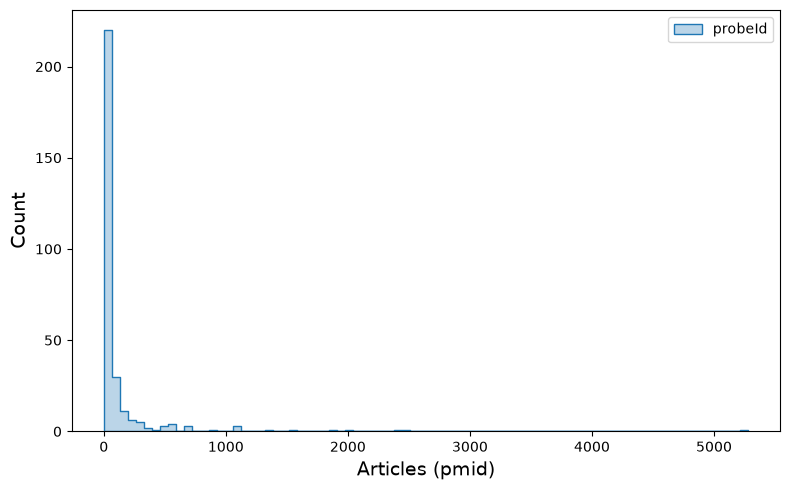

In [22]:
gr = ner_triplets_ptpairs.groupby('probeId').agg({'pmid': 'nunique'}).sort_values(by=['pmid']).reset_index()
print(gr.pmid.max(), gr.pmid.min(), gr.pmid.median())

# Create the figure and axes
plt.figure(figsize=(8, 5)) 

# Use sns.histplot instead of kdeplot
# element='step' gives it a clean outline look similar to your density plot
sns.histplot(data=gr, x='pmid', label='probeId', element='step', fill=True, alpha=0.3, bins=80)

plt.xlabel('Articles (pmid)', fontsize=14)
plt.ylabel('Count', fontsize=14) # Note: Changed from 'Density' to 'Count'
plt.legend()
plt.tight_layout()

plt.savefig((FIGURES_DIR / 'ner_probes_pmid_distribution_hist.png'), dpi=400)
plt.savefig((FIGURES_DIR / 'ner_probes_pmid_distribution.svg'), dpi=400)
plt.show()

In [23]:
probe_dis = ner_triplets_ptpairs.groupby('probeId')[['targetId','diseaseId']].nunique().sort_values(by=['targetId']).reset_index()
print(probe_dis.targetId.min(),probe_dis.targetId.max(),probe_dis.targetId.median(),probe_dis.diseaseId.min(),probe_dis.diseaseId.max(),probe_dis.diseaseId.median())
#probe_dis = ner_triplets_ptpairs.groupby('probeId').agg({'diseaseId': 'nunique'}).sort_values(by=['pmid']).reset_index()

1 5 1.0 1 934 11.0


/var/folders/cq/_q5gnhz555511kpb32c3k8940000gp/T/ipykernel_50895/1516101316.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=probe_dis,
/var/folders/cq/_q5gnhz555511kpb32c3k8940000gp/T/ipykernel_50895/1516101316.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=probe_dis,


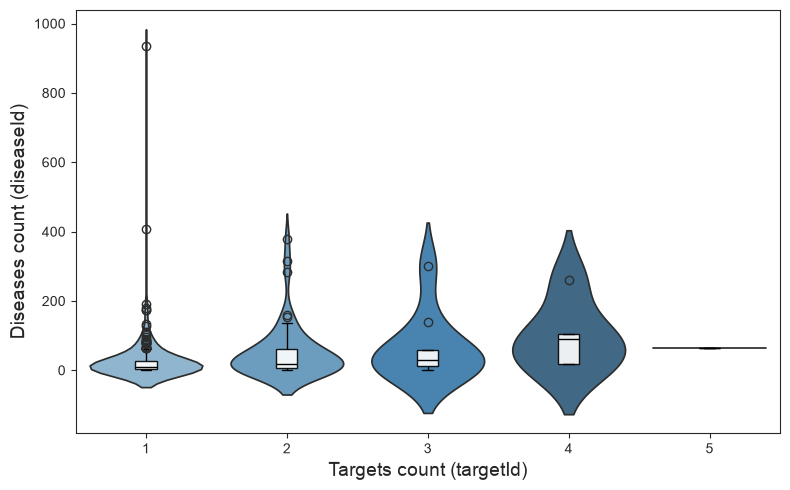

diseases count median for cases 1-3 targets 11.0
target median 1.0


In [24]:
# Set the aesthetic style
sns.set_style("ticks")

# Create the figure and axes
plt.figure(figsize=(8, 5)) # Optional: Adjust figure size
ax = plt.gca() # Get the current axes

# 1. Create the violin plot WITHOUT the inner element
sns.violinplot(data=probe_dis,
               x='targetId',
               y='diseaseId',
               inner=None,       # Draw violin shape only
               palette='Blues_d',# Use the palette for violin color
               ax=ax)            # Specify the axes to draw on

# 2. Overlay the boxplot with custom styling
sns.boxplot(data=probe_dis,
            x='targetId',
            y='diseaseId',
            showfliers=True,   # Hide outliers here (violin shows full range)
            width=0.15,         # Make boxes narrow to fit inside violins
            palette='Blues_d',  # Use same palette for consistency (optional)
            boxprops=dict(facecolor='white', edgecolor='black', alpha=0.9), # *** Set facecolor to white ***
            medianprops=dict(color='black'), # Style median line
            whiskerprops=dict(color='black'),# Style whiskers
            capprops=dict(color='black'),    # Style caps
            ax=ax)              # Specify the same axes

# Improve appearance
sns.despine()

# Set labels and layout
plt.xlabel('Targets count (targetId)', fontsize=14)
plt.ylabel('Diseases count (diseaseId)', fontsize=14)

# --- Ensure all four spines are visible to form a box ---
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

plt.tight_layout()


# Save and show the figure (updated filename)
plt.savefig((FIGURES_DIR / 'ner_probe_tar_dis_distribution.png'), dpi=400)
plt.savefig((FIGURES_DIR / 'ner_probe_tar_dis_distribution.svg'), dpi=400)
plt.show()

print('diseases count median for cases 1-3 targets',probe_dis[probe_dis.targetId < 4].diseaseId.median())
print('target median',probe_dis.targetId.median())

In [25]:
#checking the 3 most frequents disease in the heatmap
grt = ner_triplets_ptpairs.groupby(['diseaseId']).agg({'targetId': 'nunique'}).sort_values(by=['targetId']).reset_index()
print(grt[grt.diseaseId.isin(['EFO_0003060','EFO_0000616','MONDO_0004992'])])

          diseaseId  targetId
1740  MONDO_0004992       167


In [26]:
gr = ner_triplets_ptpairs.groupby(['targetId', 'diseaseId']).agg({'pmid': 'nunique'}).sort_values(by=['pmid']).reset_index()
print(gr.pmid.min(),gr.pmid.max())
grs = gr[gr.pmid>50]
#display(grs)
print(grs.targetId.nunique(), grs.diseaseId.nunique())
pivot_table = grs.pivot_table(index="targetId", columns="diseaseId", values="pmid")

1 1212
39 85


In [27]:
interesting = gr[gr.pmid>500]
#display(interesting.sort_values(by='pmid'))

### NUMBERS

In [28]:
#display(ner_triplets_ptpairs.columns)
# plotting eevidence general
dfcounts = ner_triplets_ptpairs.copy()

# Combine 'TARGET' and 'DISEASE' columns into 'TARGET-DISEASE'
dfcounts['target-disease'] = dfcounts['targetId'] + '-' + dfcounts['diseaseId']

### Most frequent chemical probes

In [29]:
# Group by probeId and calculate all distinct counts in one go
result_df = dfcounts.groupby('probeId').agg(
    probeName=('probe', 'first'),           # Get the probe name
    pmids=('pmid', 'nunique'),          # Count unique PMIDs
    diseases=('diseaseId', 'nunique'),  # Count unique Disease IDs
    targets=('targetId', 'nunique')     # Count unique Target IDs
).reset_index()

# Convert the 'probe' column to lowercase
result_df['probeName'] = result_df['probeName'].str.lower()

# Sort by number of pmids (descending) to match your previous view
result_df = result_df.sort_values(by=['pmids'], ascending=False)
result_df.to_csv((RESULTS_DIR / 'ner_probes.tsv'), sep='\t', index=False)

### Most frequent diseases

In [30]:
# Group by probeId and calculate all distinct counts in one go
result_df = dfcounts.groupby('diseaseId').agg(
    diseaseName=('name', 'first'),           # Get the probe name
    pmids=('pmid', 'nunique'),          # Count unique PMIDs
    targets=('targetId', 'nunique'),  # Count unique Disease IDs
    probes=('probeId', 'nunique')     # Count unique Target IDs
).reset_index()

# Sort by number of pmids (descending) to match your previous view
result_df = result_df.sort_values(by=['pmids'], ascending=False)
dis_freq = result_df.diseaseId.to_list()[:34] #+4 that are later filtered out
result_df.to_csv((RESULTS_DIR / 'ner_diseases.tsv'), sep='\t', index=False)


### Most frequent targets

In [31]:
# Group by probeId and calculate all distinct counts in one go
result_df = dfcounts.groupby('targetId').agg(
    geneName=('gene', 'first'),           # Get the probe name
    pmids=('pmid', 'nunique'),          # Count unique PMIDs
    diseases=('diseaseId', 'nunique'),  # Count unique Disease IDs
    probes=('probeId', 'nunique')     # Count unique Target IDs
).reset_index()

# Sort by number of pmids (descending) to match your previous view
result_df = result_df.sort_values(by=['pmids'], ascending=False)
tar_freq = result_df.targetId.to_list()[:30]
result_df.to_csv((RESULTS_DIR / 'ner_targets.tsv'), sep='\t', index=False)

### Clustering diseasea according to ontology

In [32]:
from helpers.tools import find_preferred_ta
ner_triplets_ptpairs['preferredTA'] = ner_triplets_ptpairs['therapeuticAreas'].apply(find_preferred_ta)
print(ner_triplets_ptpairs.columns)

Index(['diseaseId', 'targetId', 'datasourceId', 'datatypeId', 'score',
       'evidenceCount', 'pmid', 'date', 'section', 'probeId', 'sentence',
       'probe', 'inchiKey', 'gene', 'allcurationYears', 'allpublicationYears',
       'allstudyYears', 'datedEvidenceStatus', 'name', 'therapeuticAreas',
       'drugId', 'maxClinicalStage', 'clinicalStageRank',
       'hasClinicalIndication', 'articleType', 'maxPhase', 'probe_data',
       'preferredTA'],
      dtype='object')


### Heatmap zoom in to most common targets/diseases pairs
plots the 30 most frequent targets and 30 most frequent diseases


X-Axis Disease Sorting Order (for validation)


,diseaseId,name,preferredTA,sort_priority
0,EFO_0000544,infection,GO_0008150,0
1,MONDO_0005575,colorectal cancer,EFO_0010282,1
2,MONDO_0024331,colorectal carcinoma,EFO_0010282,1
3,MONDO_0007256,hepatocellular carcinoma,EFO_0010282,1
4,MONDO_0005184,pancreatic ductal adenocarcinoma,EFO_0010282,1
5,MONDO_0004975,Alzheimer disease,MONDO_0002025,1
6,MONDO_0009693,plasma cell myeloma,MONDO_0005046,1
7,MONDO_0018177,glioblastoma,MONDO_0005071,1
8,MONDO_0021040,pancreatic neoplasm,MONDO_0005151,1
9,MONDO_0004948,B-cell chronic lymphocytic leukemia,MONDO_0005570,1


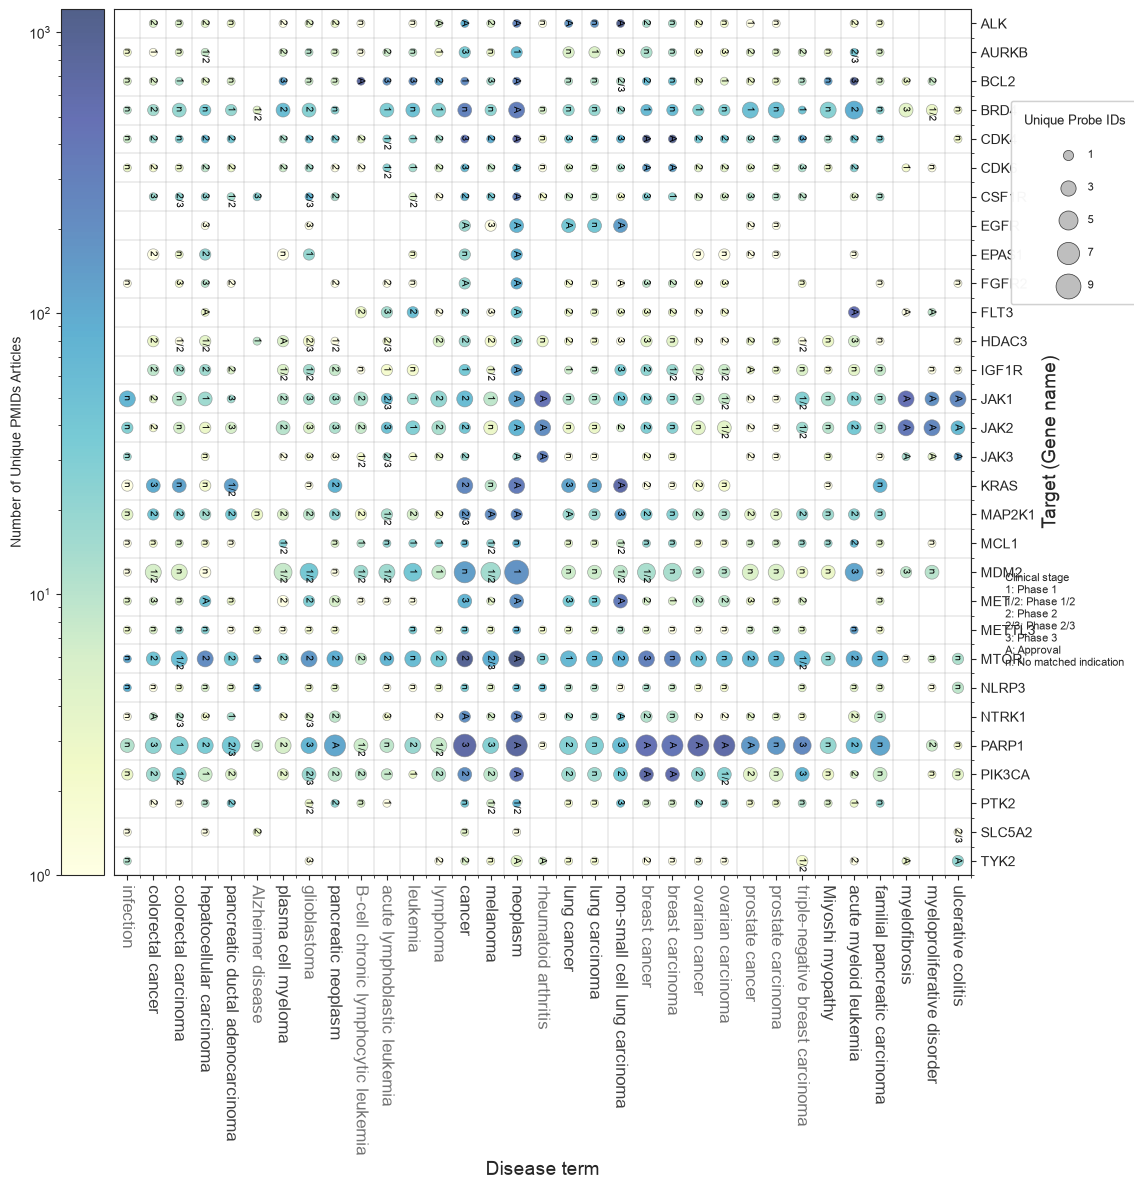

In [33]:
#print(dis_freq) #from previous code cells
#print(tar_freq)
subs = ner_triplets_ptpairs[ner_triplets_ptpairs.diseaseId.str.startswith(('EFO', 'MONDO'), na=False)]
subs['maxPhase'] = pd.to_numeric(subs['maxPhase'], errors='coerce')

# 1. Create small, unique mapping tables
disease_map = subs[['diseaseId', 'name', 'preferredTA']].drop_duplicates(subset=['diseaseId'])
target_map = subs[['targetId', 'gene']].drop_duplicates()

# 2. Aggregate data using only the necessary columns
grouped_data = subs.groupby(['targetId', 'diseaseId']).agg(
    pmid_count=('pmid', 'nunique'),
    probeId_count=('probeId', 'nunique'),
    max_clinical_stage_rank=('clinicalStageRank', 'max') 
).reset_index()

# 3. Filter aggregated data to include most frequent targets and most frequent diseases
grouped_data = grouped_data[
    (grouped_data.diseaseId.isin(dis_freq)) & 
    (grouped_data.targetId.isin(tar_freq))
]

### filter for most frequent T-D pairs
#grouped_data = grouped_data[
#    (grouped_data.diseaseId.isin(sample.diseaseId.unique().tolist())) & 
#    (grouped_data.targetId.isin(sample.targetId.unique().tolist()))
#]

# 4. Merge with the small, efficient mapping tables
grouped_data = grouped_data.merge(disease_map, on='diseaseId', how='left')
grouped_data = grouped_data.merge(target_map, on='targetId', how='left')

# 5. Select final columns.
#display(grouped_data[['diseaseId','name']].drop_duplicates())
grouped_data = grouped_data[[
    'gene', 'name', 'diseaseId', 'preferredTA', 
    'probeId_count', 'pmid_count', 'max_clinical_stage_rank' 
]]

if grouped_data.empty:
    print("No association data found to plot.")
else:
    # 2. Map IDs to numerical coordinates
    unique_targets = sorted(grouped_data['gene'].unique()) # Y-axis (alphabetical)
    
    # Get unique (diseaseId, disease name, preferredTA) pairs from the final data
    # This represents every unique disease that will be plotted.
    disease_info_table = grouped_data[['diseaseId', 'name', 'preferredTA', ]].drop_duplicates()
    priority_list = ['GO_0008150', 'EFO_0000651', 'EFO_0000618']
    disease_info_table['sort_priority'] = (~disease_info_table['preferredTA'].isin(priority_list)).astype(int)
    
    # Sort by 'preferredTA' first, then 'diseaseName' alphabetically within each TA
    sorted_disease_info = disease_info_table.sort_values(
        by=['sort_priority','preferredTA', 'name']
    ).reset_index(drop=True)
    
    # Create the final list of disease names for the plot axis
    unique_diseases = sorted_disease_info['name'].tolist()
    
    # This will display the exact order of diseases as they will appear
    # on the X-axis, along with their ID and TA.
    print("\n" + "="*40)
    print("X-Axis Disease Sorting Order (for validation)")
    print("="*40)
    display(sorted_disease_info)
    print("\n")

    # Get the unique TA values in the order they appear
    unique_tas = sorted_disease_info['preferredTA'].unique()
    # Define your two alternating colors
    color_2 = '#404040' # lighter blue
    color_1 = '#737373' # Dark blue
    # Create dictionary mapping each TA to one of the two colors based on its order
    # i % 2 == 0 checks if the index is even.
    ta_to_color = {ta: (color_1 if i % 2 == 0 else color_2) for i, ta in enumerate(unique_tas)}
    # This list is in the *exact* same order as your x-axis labels
    label_tas_in_order = sorted_disease_info['preferredTA'].tolist()

    # 4. Create the mapping dictionaries
    target_to_int = {target: i for i, target in enumerate(unique_targets)}
    disease_to_int = {disease: i for i, disease in enumerate(unique_diseases)}

    grouped_data['target_int'] = grouped_data['gene'].map(target_to_int)
    grouped_data['disease_int'] = grouped_data['name'].map(disease_to_int)

    # Compact display labels only: retain the existing clinical-stage ordering.
    from helpers.clinical_stages import STAGE_RANK, RANK_STAGE
    compact_stages = {
        'UNKNOWN': ('?', 'Unknown stage'),
        'PRECLINICAL': ('PC', 'Preclinical'),
        'IND': ('IND', 'IND'),
        'EARLY_PHASE_1': ('E1', 'Early phase 1'),
        'PHASE_1': ('1', 'Phase 1'),
        'PHASE_1_2': ('1/2', 'Phase 1/2'),
        'PHASE_2': ('2', 'Phase 2'),
        'PHASE_2_3': ('2/3', 'Phase 2/3'),
        'PHASE_3': ('3', 'Phase 3'),
        'PREAPPROVAL': ('PA', 'Preapproval'),
        'PHASE_4': ('4', 'Phase 4'),
        'APPROVAL': ('A', 'Approval'),
        'WITHDRAWAL': ('W', 'Withdrawal'),
    }
    def bubble_stage_label(rank):
        if pd.isna(rank):
            return 'n'
        return compact_stages[RANK_STAGE[int(rank)]][0]

    grouped_data['clinical_stage_label'] = grouped_data['max_clinical_stage_rank'].apply(
        bubble_stage_label
    )
    # Explain only categories present in this heatmap.
    plotted_labels = set(grouped_data['clinical_stage_label'])
    stage_key = ['Clinical stage']
    for stage in sorted(compact_stages, key=STAGE_RANK.get):
        symbol, description = compact_stages[stage]
        if symbol in plotted_labels:
            stage_key.append(f'{symbol}: {description}')
    if 'n' in plotted_labels:
        stage_key.append('n: No matched indication')

    # 3. Prepare data for scatter plot 
    x_coords = grouped_data['disease_int'] # Bubbles centered at integers (0, 1, ...)
    y_coords = grouped_data['target_int'] # Bubbles centered at integers (0, 1, ...)
    bubble_sizes_raw = grouped_data['probeId_count']
    bubble_colors = grouped_data['pmid_count']

    # Bubble Size Scaling
    min_size = 20
    scale_factor = 300
    scaled_sizes = (bubble_sizes_raw / bubble_sizes_raw.max()) * scale_factor

    # Figure Size 
    fig_width = 12
    fig_height = 12
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    # Color normalization (same as before)
    min_color_val = bubble_colors[bubble_colors > 0].min() if (bubble_colors > 0).any() else 1
    norm = LogNorm(vmin=min_color_val, vmax=bubble_colors.max()) if bubble_colors.max() > 0 else None

    # 6. Create the scatter plot (remove zorder)
    scatter = ax.scatter(
        x=x_coords,
        y=y_coords,
        s=scaled_sizes,
        c=bubble_colors,
        cmap='YlGnBu',
        norm=norm,
        alpha=0.7,
        edgecolors='grey',
        linewidth=0.5
        # No zorder needed here
    )

    # Add compact clinical-stage text inside bubbles  
    for index, row in grouped_data.iterrows():
        ax.text(
        x=row['disease_int'],  
        y=row['target_int'],
            s=str(row['clinical_stage_label']).strip(), # <--- Good practice to strip whitespace just in case
            ha='center',
            va='center_baseline',
            fontsize=7,
            color='black',
            fontweight='normal',
            rotation=-90
        )

    # Set MAJOR ticks at integer positions (where labels should appear)
    ax.set_xticks(np.arange(len(unique_diseases)))
    ax.set_xticklabels(unique_diseases, rotation=-90, fontsize=12) # Keep labels at integers
    ax.grid(False, which='major')
    # Get the list of tick label objects
    xtick_labels = ax.get_xticklabels()
    # Loop through the labels and apply the correct color
    # We check the length to avoid errors if something went wrong
    if len(xtick_labels) == len(label_tas_in_order):
        for i, label in enumerate(xtick_labels):
            # Get the preferredTA for this specific label
            ta = label_tas_in_order[i]
            # Get the corresponding color from our map
            color = ta_to_color[ta]
            # Set the label's color
            label.set_color(color)
    else:
        print("Warning: Mismatch between label count and TA data. Colors not applied.")
    ax.grid(False, which='major')

    ax.set_yticks(np.arange(len(unique_targets)))
    # Apply y-label skipping if desired (using major ticks)
    max_labels_y = 50
    ytick_skip = max(1, len(unique_targets) // max_labels_y)
    ax.set_yticklabels(unique_targets[::ytick_skip], fontsize=10)
    # If showing all y-labels: ax.set_yticklabels(unique_targets, fontsize=7)
    # Make sure the corresponding ax.set_yticks reflects the skipping:
    ax.set_yticks(np.arange(len(unique_targets))[::ytick_skip]) # Only set ticks where labels are shown

    # Set MINOR ticks at the halfway points (.5 positions)
    ax.xaxis.set_minor_locator(FixedLocator(np.arange(len(unique_diseases)) + 0.5))
    ax.yaxis.set_minor_locator(FixedLocator(np.arange(len(unique_targets)) + 0.5))

    # Draw the grid using MINOR ticks
    ax.grid(True, which='minor', linestyle='-', linewidth=0.3, color='darkgrey')

    # Ensure grid is drawn BEHIND scatter points ---
    ax.set_axisbelow(True)

    # Set axis limits to align with the minor grid lines
    ax.set_xlim(-0.5, len(unique_diseases) - 0.5)
    ax.set_ylim(-0.5, len(unique_targets) - 0.5)

    # Invert y-axis
    ax.invert_yaxis()

    # Labels and Title 
    ax.set_xlabel('Disease term', fontsize=14)
    ax.set_ylabel('Target (Gene name)', fontsize=14)
    ax.yaxis.tick_right()
    ax.yaxis.set_label_position("right")

    # Color Bar 
    cbar = fig.colorbar(scatter, ax=ax, label='Number of Unique PMIDs Articles', location='left', pad=0.01)

    # Get unique positive probe counts from the actual data
    # bubble_sizes_raw is grouped_data['probeId_count']
    unique_positive_counts = np.unique(bubble_sizes_raw[bubble_sizes_raw > 0].astype(int))

    if len(unique_positive_counts) == 0:
        legend_probe_counts = np.array([])  # No data for legend
    elif len(unique_positive_counts) <= 5:
        # If 5 or fewer unique positive counts, use all of them for the legend
        legend_probe_counts = unique_positive_counts
    else:
        # If more than 5 unique positive counts, pick up to 5 representative values using linspace
        min_val = unique_positive_counts.min()
        max_val = unique_positive_counts.max()
        # Generate 5 values, including min and max, then ensure they are unique integers
        legend_probe_counts = np.unique(np.linspace(min_val, max_val, num=5).astype(int))

    legend_handles = []
    legend_labels = []

    # Determine the overall maximum raw size for consistent scaling in the legend
    # This should match how 'scaled_sizes' for the main plot was determined
    max_raw_overall_for_scaling = bubble_sizes_raw.max() if not bubble_sizes_raw.empty and bubble_sizes_raw.max() > 0 else 0

    if len(legend_probe_counts) > 0:
        for count_val in legend_probe_counts:
            # Apply the same scaling logic as used for the main plot's bubbles:
            # scaled_sizes = min_size + (bubble_sizes_raw / bubble_sizes_raw.max()) * scale_factor if bubble_sizes_raw.max() > 0 else min_size
            if max_raw_overall_for_scaling > 0:
                scaled_size_legend = min_size + (count_val / max_raw_overall_for_scaling) * scale_factor
            else:
                # Fallback if no positive max_raw_overall (e.g. all counts are 0 or data is empty)
                # This case implies all bubbles would be min_size.
                # If count_val itself can be 0 and min_size is for positive counts, adjust as needed.
                scaled_size_legend = min_size

            legend_handles.append(plt.scatter([], [], s=scaled_size_legend, c='darkgrey', alpha=0.7, edgecolors='black', linewidth=0.5))
            legend_labels.append(f'{count_val}') # Label is the raw probeId_count

        if legend_handles: # Ensure there's something to add to the legend
            size_legend = ax.legend(
                handles=legend_handles, labels=legend_labels, title='Unique Probe IDs',
                loc='upper left', bbox_to_anchor=(1.04, 0.9), # Your existing legend position
                labelspacing=2.0, borderpad=1.2, frameon=True, fontsize=8, title_fontsize=9 # Your existing legend styling
            )
            ax.add_artist(size_legend) # Add this legend to the plot

    # Separate annotation key below the probe-count legend.
    ax.text(1.04, 0.35, '\n'.join(stage_key), transform=ax.transAxes,
            ha='left', va='top', fontsize=8)

    # Layout adjustment
    plt.tight_layout()#rect=[0.03, 0.10, 0.90, 0.95])
    #plt.savefig((FIGURES_DIR / 'ner_probes_heatmap_zoom.png'), dpi=400)
    plt.savefig((FIGURES_DIR / 'ner_probes_heatmap_zoom.svg'), dpi=400)
    plt.show()


### Heatmap zoom in to most novel/interesting targets/diseases pairs
The heatmap shows target and disease where:
* the first chemical probe literature evidence for the pair was reported within the last 5 years
* at least one of the dots (evidence links) has 2 or more chemical probes reported.
* only dots (links) with 15 or less articles found
* no clinical trial reported for the pair (max_phase < -1)

In [34]:
## Disease ids that have been curated and are wrong. They are to be excluded form the plot but kept in the main dataset
bad_ner_ids = pd.read_csv((INPUT_DIR / 'disease_term_black_list.tsv'), sep=',')['diseaseId'].tolist()


X-Axis Disease Sorting Order (for validation)


,diseaseId,name,preferredTA
0,EFO_0004272,anemia (phenotype),EFO_0000651
1,MONDO_0003019,potassium deficiency disease,OTAR_0000020
2,MONDO_0000328,hyperphosphatemia,OTAR_0000020
3,MONDO_0021187,hyperlipidemia,OTAR_0000020
4,MONDO_0002177,hyperinsulinism,OTAR_0000020
...,...,...,...
185,MONDO_0005580,esophageal squamous cell carcinoma,EFO_0010282
186,MONDO_0024331,colorectal carcinoma,EFO_0010282
187,MONDO_0005008,colorectal adenocarcinoma,EFO_0010282
188,MONDO_0005401,colonic neoplasm,EFO_0010282


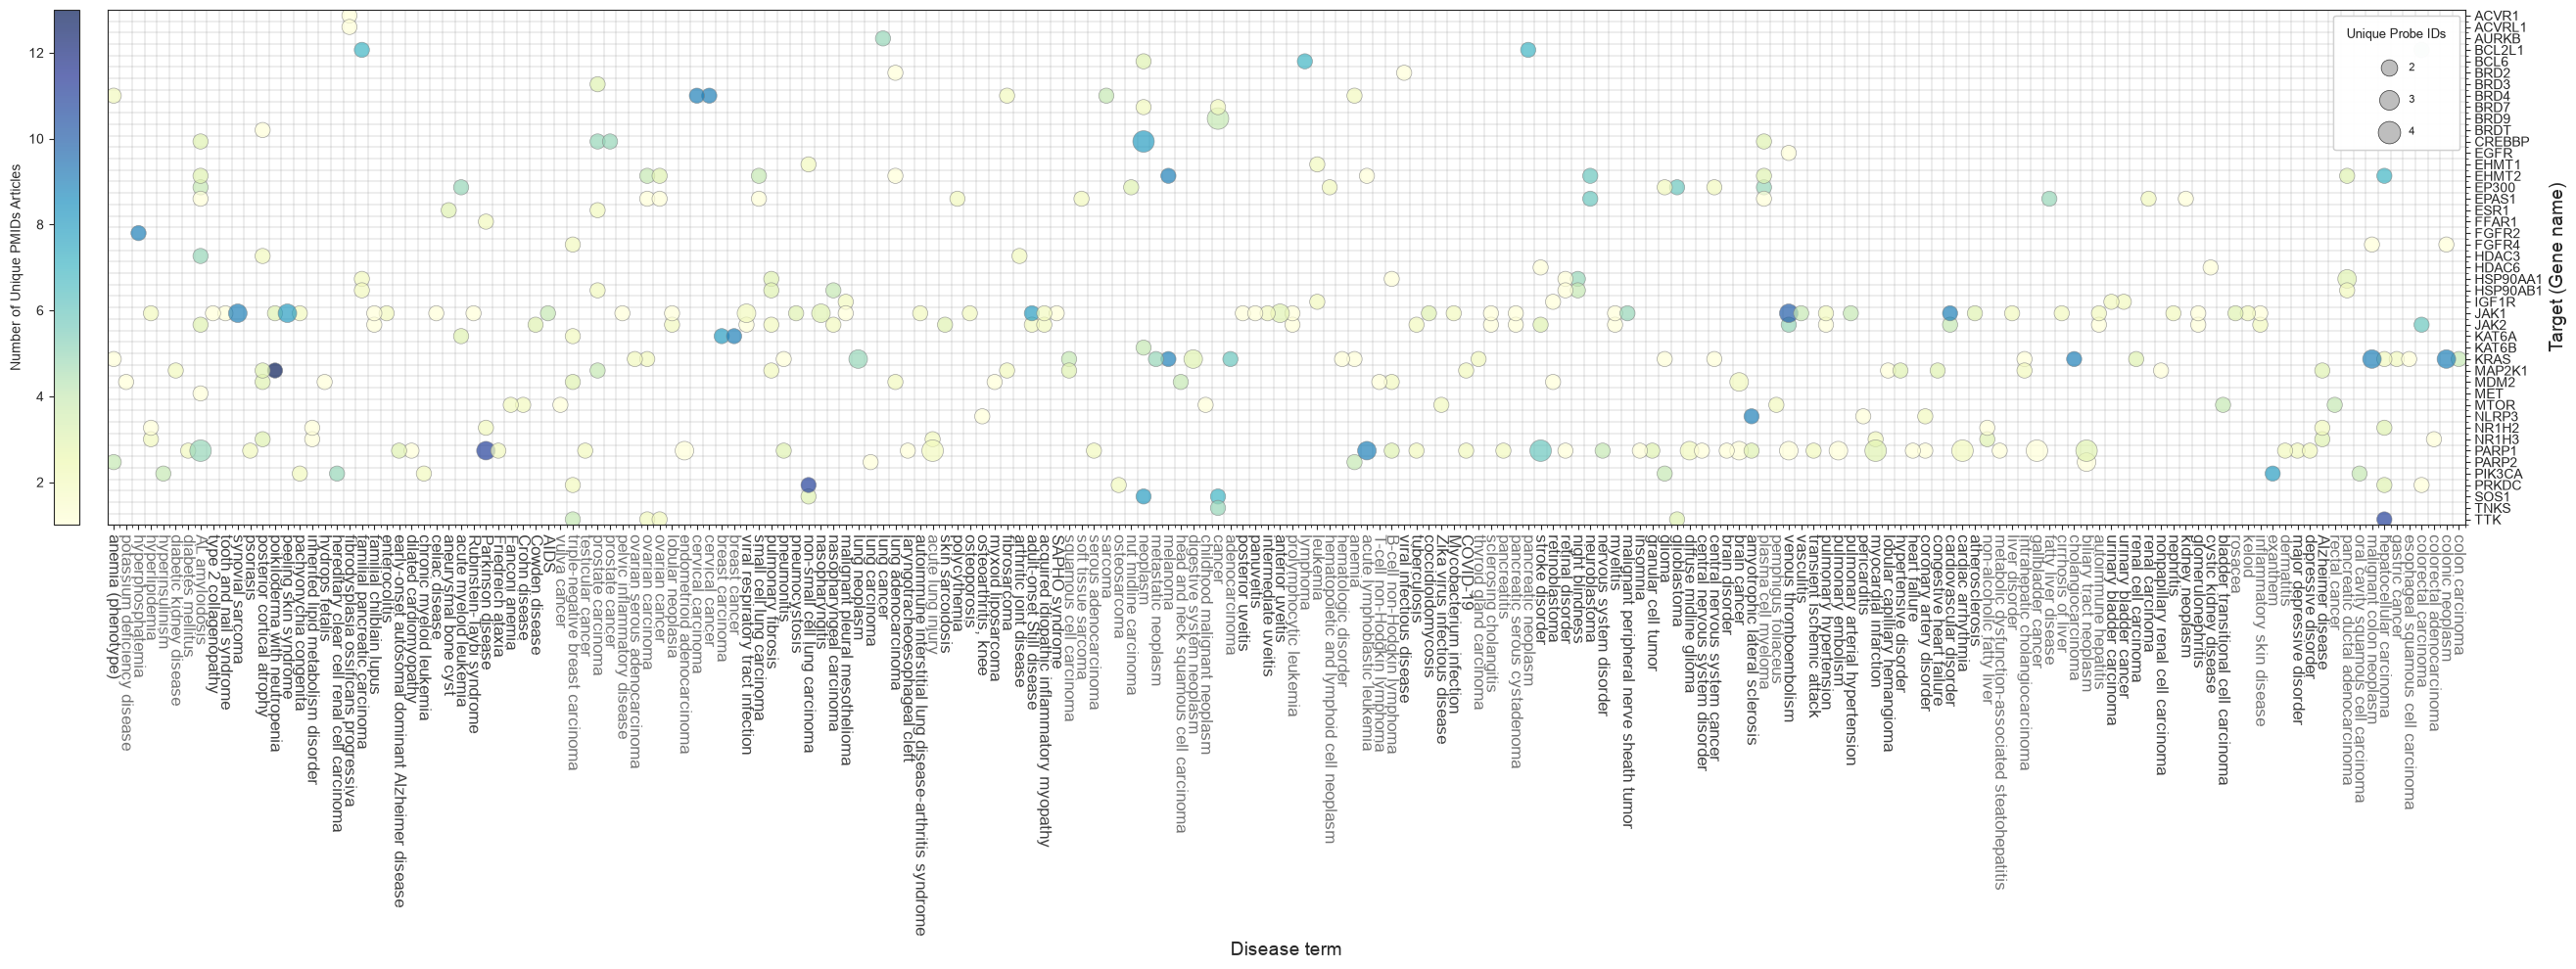

In [35]:
subs3 = ner_triplets_ptpairs[ner_triplets_ptpairs.diseaseId.str.startswith(('EFO', 'MONDO'), na=False)]
subs3 = subs3[(~subs3['diseaseId'].isin(bad_ner_ids)) & (subs3['preferredTA'] != 'EFO_0001444')]
subs3 = subs3.dropna(subset=['diseaseId', 'preferredTA', 'name'])

# 0. Create mask for target-disease pairs with first evidence in last 5 years
subs3['date'] = pd.to_datetime(subs3['date']) 
start_date = pd.to_datetime('2020-01-01')
end_date = pd.to_datetime('2025-12-31') 
group_min_date = subs3.groupby(['diseaseId', 'targetId'])['date'].transform('min') 
group_max_date = subs3.groupby(['diseaseId', 'targetId'])['date'].transform('max') 
datemask = (group_min_date >= start_date) & (group_max_date <= end_date)
subs3_fi = subs3[datemask].copy()

# 1. Create small, unique mapping tables
disease_map = subs3_fi[['diseaseId', 'name', 'preferredTA']].drop_duplicates(subset=['diseaseId'])
target_map = subs3_fi[['targetId', 'gene']].drop_duplicates()

# 2. Aggregate data using only the necessary columns
subs3_fi['clinicalStageRank'] = pd.to_numeric(subs3_fi['clinicalStageRank'], errors='raise')
grouped_data = subs3_fi.groupby(['targetId', 'diseaseId']).agg(
    pmid_count=('pmid', 'nunique'),
    probeId_count=('probeId', 'nunique'),
    max_clinical_stage_rank=('clinicalStageRank', 'max') # Clinical stage rank is for the T-D pair; maxPhase is separate ChEMBL probe metadata.
).reset_index()

# 3. Subset aggregated data to most novel targets and most novel diseases
strict=True
if strict:
    #Filter aggregated data to only novel targets and diseases pairs. (The two steps filter ensures adding all bubles for the pair and not just the one with 2 chemical probes or more)
    grouped_data = grouped_data[
        (grouped_data['probeId_count'] > 1) & 
        (grouped_data['pmid_count'] > 0) & (grouped_data['pmid_count'] < 21) &
        (grouped_data['max_clinical_stage_rank'].isna()) # Only no matched indication; UNKNOWN has rank 0 and is excluded.
        ] 
    fig_width = 30
    fig_height = 10
else:
    #Filter aggregated data to only novel targets and diseases pairs. (The two steps filter ensures adding all bubles for the pair and not just the one with 2 chemical probes or more)
    grouped_data = grouped_data[
        (grouped_data['probeId_count'] > 0) & 
        (grouped_data['pmid_count'] > 0) & (grouped_data['pmid_count'] < 90)# Only no matched indication; UNKNOWN has rank 0 and is excluded. 
        ] 
    fig_width = 30
    fig_height = 15

# 4. Merge with the small, efficient mapping tables
grouped_data = grouped_data.merge(disease_map, on='diseaseId', how='left')
grouped_data = grouped_data.merge(target_map, on='targetId', how='left')
grouped_data[['targetId','gene', 'diseaseId', 'name', 'preferredTA', 'probeId_count', 'pmid_count', 'max_clinical_stage_rank']].to_csv((RESULTS_DIR / 'ner_probes_triplets_novel.tsv'), sep='\t', index=False)

# 5. Select final columns. 
#display(grouped_data[['diseaseId','diseaseName']].drop_duplicates())
grouped_data = grouped_data[['gene', 'name', 'diseaseId', 'preferredTA', 'probeId_count', 'pmid_count', 'max_clinical_stage_rank']]

if grouped_data.empty:
    print("No association data found to plot.")
else:
    # 2. Map IDs to numerical coordinates
    unique_targets = sorted(grouped_data['gene'].unique()) # Y-axis (alphabetical)
    
    # Get unique (diseaseId, disease name, preferredTA) pairs from the final data
    # This represents every unique disease that will be plotted.
    disease_info_table = grouped_data[['diseaseId', 'name', 'preferredTA', ]].drop_duplicates()
    
    # Sort by 'preferredTA' first, then 'diseaseName' alphabetically within each TA
    #sorted_disease_info = disease_info_table.sort_values(
    #    by=['preferredTA', 'name'],
    #    ascending=[False, False]
    #).reset_index(drop=True)

    # Define the preferredTA IDs to move to the left of the plot
    tas_to_move_left = [
        'EFO_0000651',  
        'EFO_0001444',   
        'GO_0008150'
    ]

    # Separate your data into two DataFrames
    special_labels_df = disease_info_table[disease_info_table['preferredTA'].isin(tas_to_move_left)]
    normal_labels_df = disease_info_table[~disease_info_table['preferredTA'].isin(tas_to_move_left)]
    # Sort special TA
    special_labels_sorted = special_labels_df.sort_values(
        by=['preferredTA', 'name'],
        ascending=[True, False]
    )
    #Sort normal TA
    normal_labels_sorted = normal_labels_df.sort_values(
        by=['preferredTA', 'name'],
        ascending=[False, False]
    )
    #Stack them back together, with the special groups first
    sorted_disease_info = pd.concat([special_labels_sorted, normal_labels_sorted]).reset_index(drop=True)
    
    # Create the final list of disease names for the plot axis
    unique_diseases = sorted_disease_info['name'].tolist()
    
    # This will display the exact order of diseases as they will appear
    # on the X-axis, along with their ID and TA.
    print("\n" + "="*40)
    print("X-Axis Disease Sorting Order (for validation)")
    print("="*40)
    display(sorted_disease_info)
    print("\n")

    # Get the unique TA values in the order they appear
    unique_tas = sorted_disease_info['preferredTA'].unique()
    # Define your two alternating colors
    color_1 = '#404040' # lighter blue
    color_2 = '#737373' # Dark blue
    # Create dictionary mapping each TA to one of the two colors based on its order
    # i % 2 == 0 checks if the index is even.
    ta_to_color = {ta: (color_1 if i % 2 == 0 else color_2) for i, ta in enumerate(unique_tas)}
    # This list is in the *exact* same order as your x-axis labels
    label_tas_in_order = sorted_disease_info['preferredTA'].tolist()

    # 4. Create the mapping dictionaries
    target_to_int = {target: i for i, target in enumerate(unique_targets)}
    disease_to_int = {disease: i for i, disease in enumerate(unique_diseases)}

    grouped_data['target_int'] = grouped_data['gene'].map(target_to_int)
    grouped_data['disease_int'] = grouped_data['name'].map(disease_to_int)

    # 3. Prepare data for scatter plot 
    x_coords = grouped_data['disease_int'] # Bubbles centered at integers (0, 1, ...)
    y_coords = grouped_data['target_int'] # Bubbles centered at integers (0, 1, ...)
    bubble_sizes_raw = grouped_data['probeId_count']
    bubble_colors = grouped_data['pmid_count']

    # 4. Bubble Size Scaling
    min_size = 20
    scale_factor = 250
    scaled_sizes = (bubble_sizes_raw / bubble_sizes_raw.max()) * scale_factor

    # 5. Figure Size 
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    # 6. Color normalization (now Linear)
    # By setting norm=None, matplotlib will default to a linear scale
    norm = None

    # 7. Create the scatter plot (remove zorder)
    scatter = ax.scatter(
        x=x_coords,
        y=y_coords,
        s=scaled_sizes,
        c=bubble_colors,
        cmap='YlGnBu',
        norm=norm,
        alpha=0.7,
        edgecolors='grey',
        linewidth=0.5
        # No zorder needed here
    )
        
    # 8. Set MAJOR ticks at integer positions (where labels should appear)
    ax.set_xticks(np.arange(len(unique_diseases)))
    ax.set_xticklabels(unique_diseases, rotation=-90, fontsize=12) # Keep labels at integers
    # Get the list of tick label objects
    xtick_labels = ax.get_xticklabels()
    # Loop through the labels and apply the correct color
    # We check the length to avoid errors if something went wrong
    if len(xtick_labels) == len(label_tas_in_order):
        for i, label in enumerate(xtick_labels):
            # Get the preferredTA for this specific label
            ta = label_tas_in_order[i]
            # Get the corresponding color from our map
            color = ta_to_color[ta]
            # Set the label's color
            label.set_color(color)
    else:
        print("Warning: Mismatch between label count and TA data. Colors not applied.")
    ax.grid(False, which='major')

    ax.set_yticks(np.arange(len(unique_targets)))
    # Apply y-label skipping if desired (using major ticks)
    max_labels_y = 50
    ytick_skip = max(1, len(unique_targets) // max_labels_y)
    ax.set_yticklabels(unique_targets[::ytick_skip], fontsize=10)
    # If showing all y-labels: ax.set_yticklabels(unique_targets, fontsize=7)
    # Make sure the corresponding ax.set_yticks reflects the skipping:
    ax.set_yticks(np.arange(len(unique_targets))[::ytick_skip]) # Only set ticks where labels are shown

    # 9. Set MINOR ticks at the halfway points (.5 positions)
    ax.xaxis.set_minor_locator(FixedLocator(np.arange(len(unique_diseases)) + 0.5))
    ax.yaxis.set_minor_locator(FixedLocator(np.arange(len(unique_targets)) + 0.5))

    # Draw the grid using MINOR ticks
    ax.grid(True, which='minor', linestyle='-', linewidth=0.3, color='darkgrey')

    # Ensure grid is drawn BEHIND scatter points
    ax.set_axisbelow(True)

    # Set axis limits to align with the minor grid lines
    ax.set_xlim(-0.5, len(unique_diseases) - 0.5)
    ax.set_ylim(-0.5, len(unique_targets) - 0.5)

    # 10. Invert y-axis
    ax.invert_yaxis()

    # 11. Labels and Title 
    ax.set_xlabel('Disease term', fontsize=14)
    ax.set_ylabel('Target (Gene name)', fontsize=14)
    ax.yaxis.tick_right()
    ax.yaxis.set_label_position("right")

    # Color Bar 
    cbar = fig.colorbar(scatter, ax=ax, label='Number of Unique PMIDs Articles', location='left', pad=0.01)

    # Get unique positive probe counts from the actual data
    # bubble_sizes_raw is grouped_data['probeId_count']
    unique_positive_counts = np.unique(bubble_sizes_raw[bubble_sizes_raw > 0].astype(int))

    if len(unique_positive_counts) == 0:
        legend_probe_counts = np.array([])  # No data for legend
    elif len(unique_positive_counts) <= 5:
        # If 5 or fewer unique positive counts, use all of them for the legend
        legend_probe_counts = unique_positive_counts
    else:
        # If more than 5 unique positive counts, pick up to 5 representative values using linspace
        min_val = unique_positive_counts.min()
        max_val = unique_positive_counts.max()
        # Generate 5 values, including min and max, then ensure they are unique integers
        legend_probe_counts = np.unique(np.linspace(min_val, max_val, num=5).astype(int))

    legend_handles = []
    legend_labels = []

    # Determine the overall maximum raw size for consistent scaling in the legend
    # This should match how 'scaled_sizes' for the main plot was determined
    max_raw_overall_for_scaling = bubble_sizes_raw.max() if not bubble_sizes_raw.empty and bubble_sizes_raw.max() > 0 else 0
    if len(legend_probe_counts) > 0:
        for count_val in legend_probe_counts:
            # Apply the same scaling logic as used for the main plot's bubbles
            if max_raw_overall_for_scaling > 0:
                scaled_size_legend = min_size + (count_val / max_raw_overall_for_scaling) * scale_factor
            else:
                # Fallback if no positive max_raw_overall (e.g. all counts are 0 or data is empty)
                # This case implies all bubbles would be min_size.
                # If count_val itself can be 0 and min_size is for positive counts, adjust as needed.
                scaled_size_legend = min_size
            legend_handles.append(plt.scatter([], [], s=scaled_size_legend, c='darkgrey', alpha=0.7, edgecolors='black', linewidth=0.5))
            legend_labels.append(f'{count_val}') # Label is the raw probeId_count
        if legend_handles: # Ensure there's something to add to the legend
            size_legend = ax.legend(
                handles=legend_handles, labels=legend_labels, title='Unique Probe IDs',
                loc='upper right', bbox_to_anchor=(1, 1), # Your existing legend position
                labelspacing=2.0, borderpad=1.2, frameon=True, fontsize=8, title_fontsize=9 # Your existing legend styling
            )
            ax.add_artist(size_legend) # Add this legend to the plot

    # Layout adjustment
    plt.tight_layout()
    #plt.savefig((FIGURES_DIR / 'ner_probes_heatmap_zoom_5y_strong_nc.png'), dpi=400)
    plt.savefig((FIGURES_DIR / 'ner_probes_heatmap_zoom_5y_strict.svg'), dpi=400)
    plt.show()

In [36]:
# Writing subset of novel cases
result = pd.merge(subs3, grouped_data[['gene', 'diseaseId']], on=['gene', 'diseaseId'], how='inner')

In [37]:
### CHECKING EXAMPLEs
ex = subs3[(subs3.diseaseId == 'EFO_0000770') & (subs3.gene == 'IGF1R')][['pmid','section', 'sentence', 'probe', 'maxClinicalStage']] # & (subs3.sentence.str.contains('MBC'))
ex

,pmid,section,sentence,probe,maxClinicalStage


In [38]:
ner_triplets_ptpairs.maxPhase.unique()

array([None, 4, 2, 1, 3], dtype=object)

### OT evidence for target-diseases found

10328


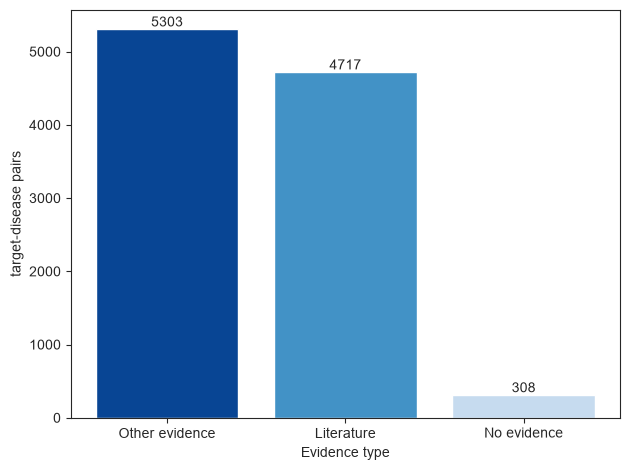

In [39]:
# plotting eevidence general
df2 = ner_triplets_ptpairs.copy()

# Combine 'TARGET' and 'DISEASE' columns into 'TARGET-DISEASE'
df2['target-disease'] = df2['targetId'] + '-' + df2['diseaseId']
print(df2['target-disease'].nunique())

# Get unique target-disease pairs for each category with the specified priority
other_pairs = set(df2[~df2['datatypeId'].isnull() & (df2['datatypeId'] != 'literature')]['target-disease'].unique())
lit_pairs = set(df2[df2['datatypeId'] == 'literature']['target-disease'].unique()) - other_pairs
none_pairs = set(df2[df2['datatypeId'].isnull()]['target-disease'].unique()) - other_pairs - lit_pairs
ecounts= [len(other_pairs), len(lit_pairs), len(none_pairs)]
evidence = ['Other evidence', 'Literature', 'No evidence']

# Define the colors to use
colors = ['#084594', '#4292c6', '#c6dbef']

# Create the bar plot
plt.bar(evidence, ecounts, color=colors)

# Add value labels on top of each bar
for i in range(len(evidence)):
    plt.text(i, ecounts[i], ecounts[i], ha='center', va='bottom')

# Add labels and title
plt.xlabel("Evidence type")
plt.ylabel("target-disease pairs")

plt.savefig((FIGURES_DIR / 'evidence.png'), dpi=600)  # Uncomment to save figures
plt.tight_layout()

# Display the plot
plt.show()

10328


array(['literature', 'known_drug', 'somatic_mutation', 'animal_model',
       'genetic_association', 'genetic_literature', 'affected_pathway',
       'rna_expression', nan], dtype=object)

[1027, 1892, 1820, 46, 95, 421, 4719, 308]


/var/folders/cq/_q5gnhz555511kpb32c3k8940000gp/T/ipykernel_50895/1450314869.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=categories, y=values, palette='Blues_r')


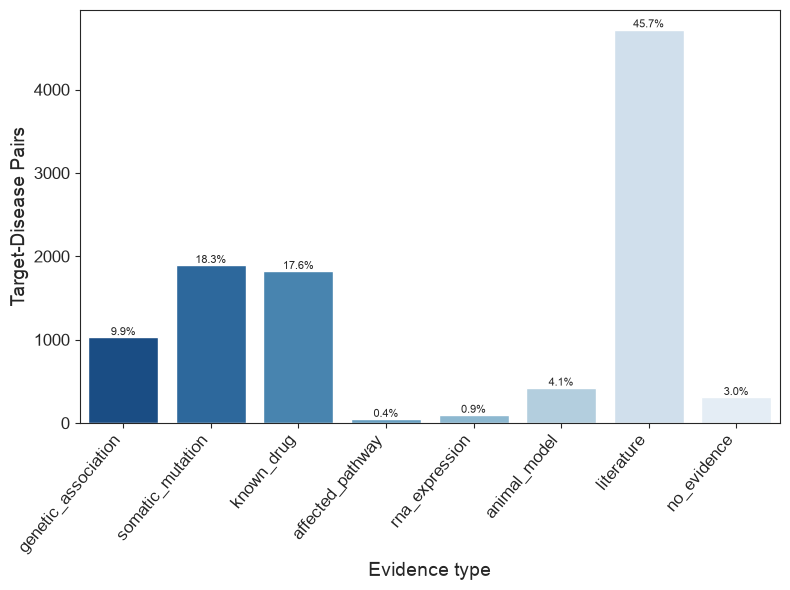

In [40]:
# plotting eevidence general
df = ner_triplets_ptpairs.copy()

# Combine 'TARGET' and 'DISEASE' columns into 'TARGET-DISEASE'
df['target-disease'] = df['targetId'] + '-' + df['diseaseId']
print(df['target-disease'].nunique())
display(df.datatypeId.unique())

ranked_categories = [
    "genetic_association",
    "somatic_mutation",
    "known_drug",
    "affected_pathway",
    "rna_expression",
    "animal_model",
    "literature",
]

counts = {}
remaining_pairs = set(df['target-disease'].unique()) # Use a set for faster removal.

for category in ranked_categories:
    category_df = df[df.datatypeId == category]
    valid_pairs = set(category_df['target-disease'].unique()) & remaining_pairs # intersection of the pairs in the category and remaining pairs.
    counts[category] = len(valid_pairs)
    remaining_pairs -= valid_pairs # Remove already counted pairs.

counts['no_evidence'] = len(remaining_pairs) # remaining pairs not in any category.

categories = list(counts.keys())
values = list(counts.values())
print(values)

# Create the barplot
plt.figure(figsize=(8, 6))
sns.barplot(x=categories, y=values, palette='Blues_r')
plt.xlabel("Evidence type", fontsize=14)
plt.ylabel("Target-Disease Pairs", fontsize=14)
plt.xticks(rotation=50, ha="right", fontsize=12)
plt.yticks(fontsize=12)

# Add value labels on top of each bar
for i in range(len(ranked_categories)+1):
    plt.text(i, values[i], f"{(values[i]*100)/sum(values):.1f}%", ha='center', va='bottom', fontsize=8)


# Set y-axis to log scale
plt.gca().set_facecolor('white')

# --- Ensure all four spines are visible to form a box ---
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

plt.tight_layout()
plt.savefig((FIGURES_DIR / 'evidence_datatype_ranking.svg'), dpi=600)  # Uncomment to save figures
plt.savefig((FIGURES_DIR / 'evidence_datatype_ranking.png'), dpi=600)  # Uncomment to save figures
plt.show()

### Evidence by max phase

In [41]:

df.groupby('maxPhase')['target-disease'].nunique()

maxPhase
1     816
2     993
3     940
4    5074
Name: target-disease, dtype: int64

/var/folders/cq/_q5gnhz555511kpb32c3k8940000gp/T/ipykernel_50895/1073491743.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dfcopy2['maxPhase'] = dfcopy2.maxPhase.fillna(int(0))


array([0, 4, 2, 1, 3])

,diseaseId,targetId,maxPhase,pmid
0,EFO_0000180,ENSG00000006071,4,1
1,EFO_0000180,ENSG00000141867,0,2
2,EFO_0000180,ENSG00000178999,3,1
3,EFO_0000180,ENSG00000198793,2,1
4,EFO_0000195,ENSG00000025434,0,2


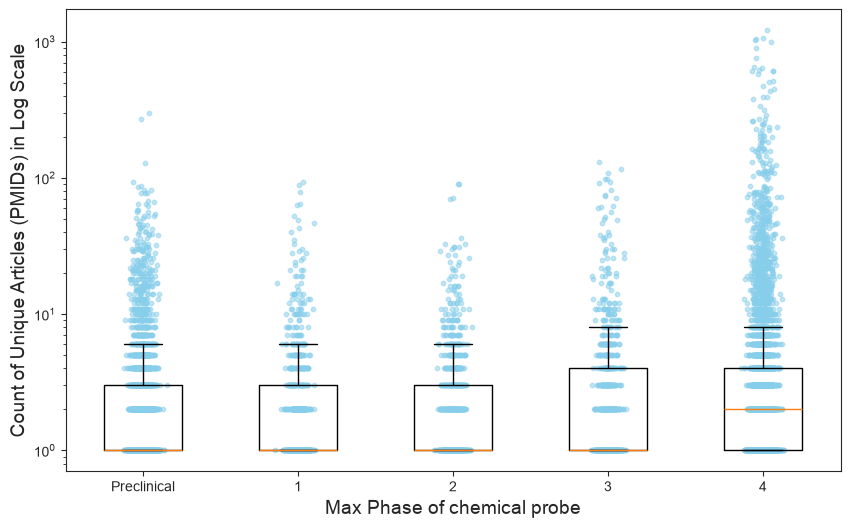

In [42]:
# Group by diseaseId, targetId, and maxphase, then count unique PMIDs
dfcopy2 = ner_triplets_ptpairs.copy()
dfcopy2['maxPhase'] = dfcopy2.maxPhase.fillna(int(0))
display(dfcopy2.maxPhase.unique())

grouped_data = dfcopy2.groupby(['diseaseId', 'targetId', 'maxPhase'])['pmid'].nunique().reset_index()
grouped_data['maxPhase'] = pd.Categorical(grouped_data['maxPhase'], categories=[0, 1, 2, 3, 4], ordered=True)

display(grouped_data.head())

# Create a list to store PMID counts for each maxphase
data_to_plot = []
max_phases = [0, 1, 2, 3, 4]
for phase in max_phases:
    data_to_plot.append(grouped_data[grouped_data['maxPhase'] == phase]['pmid'].values)

# Create the boxplot
plt.figure(figsize=(10, 6)) 

# FIX 1: Changed 'labels' to 'tick_labels' for newer Matplotlib versions
plt.boxplot(data_to_plot, tick_labels=['Preclinical', 1, 2, 3, 4], showfliers=False)

plt.xlabel("Max Phase of chemical probe", fontsize=14)
plt.ylabel('Count of Unique Articles (PMIDs) in Log Scale', fontsize=14)

# Add scatter plot points
for i, phase in enumerate(grouped_data['maxPhase'].unique()):
    x = np.random.normal(i + 1, 0.04, size=len(data_to_plot[i]))  # Add jitter
    plt.scatter(x, data_to_plot[i], alpha=0.5, s=10, color='skyblue')  # Adjust alpha and size as needed

# Set y-axis to log scale
plt.yscale('log')

# FIX 2: Explicitly define 'ax' before modifying spines and background
ax = plt.gca()

# Make background white
ax.set_facecolor('white')

# --- Ensure all four spines are visible to form a box ---
ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# plt.savefig((FIGURES_DIR / 'evidence_maxphase_scatter.svg'), dpi=600)  # Uncomment to save figures
# plt.savefig((FIGURES_DIR / 'evidence_maxphase_scatter.png'), dpi=600)  # Uncomment to save figures
plt.show()

##### Finding specific cases to discuss

In [43]:
### cases
maincopy = ner_triplets_ptpairs.copy()
maincopy['target-disease'] = maincopy['targetId'] + '-' + maincopy['diseaseId']
maincopy['maxPhase'] = maincopy.maxPhase.fillna('NA')

In [44]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None) 

In [45]:

subset = maincopy[(maincopy.datatypeId.isnull()) & (maincopy.maxPhase == 'NA')]
subset.columns
subset[['target-disease','probeId', 'probe']].drop_duplicates()

,target-disease,probeId,probe
21839,ENSG00000141867-MONDO_0019637,CHEMBL1957266,(+)-JQ1
48109,ENSG00000094631-HP_0002039,CHEMBL2018302,Tubastatin-A
61214,ENSG00000137948-MONDO_0002911,CHEMBL1957266,(+)-JQ1
69132,ENSG00000159339-MONDO_0002046,CHEMBL5081624,GSK484
74345,ENSG00000169925-MONDO_0018072,CHEMBL1957266,(+)-JQ1
118377,ENSG00000204256-MONDO_0018072,CHEMBL1957266,(+)-JQ1
184692,ENSG00000165819-MONDO_0020325,CHEMBL5405231,STM2457
185144,ENSG00000169925-MONDO_0003210,CHEMBL1957266,(+)-JQ1
206657,ENSG00000168906-HP_0002904,CHEMBL4573938,AG-270
244089,ENSG00000137948-MONDO_0009685,CHEMBL1957266,(+)-JQ1


In [46]:
#clinical-stage molecules, generating evidence that complements primary indication-focused data
maincopy[maincopy['target-disease'] == 'ENSG00000178999-MONDO_0005178'][['pmid','date','sentence', 'probeId', 'targetId', 'diseaseId', 'gene']]

,pmid,date,sentence,probeId,targetId,diseaseId,gene
970502,37634474,2023-08-25,"In conclusion, our data confirmed that abnormal mechanical strain increases the expression of AURKB by activating the Piezo1/Ca<sup>2+</sup> signaling axis, leading to destabilized heterochromatin and senescence in chondrocytes, whereas Barasertib consolidates heterochromatin, counteracts senescence and alleviates OA.",CHEMBL415049,ENSG00000178999,MONDO_0005178,AURKB
970503,37634474,2023-08-25,Barasertib impedes chondrocyte senescence and alleviates osteoarthritis by mitigating the destabilization of heterochromatin induced by AURKB.,CHEMBL415049,ENSG00000178999,MONDO_0005178,AURKB
970504,37634474,2023-08-25,"In conclusion, our data confirmed that abnormal mechanical strain increases the expression of AURKB by activating the Piezo1/Ca<sup>2+</sup> signaling axis, leading to destabilized heterochromatin and senescence in chondrocytes, whereas Barasertib consolidates heterochromatin, counteracts senescence and alleviates OA.",CHEMBL415049,ENSG00000178999,MONDO_0005178,AURKB
970505,37634474,2023-08-25,Barasertib impedes chondrocyte senescence and alleviates osteoarthritis by mitigating the destabilization of heterochromatin induced by AURKB.,CHEMBL415049,ENSG00000178999,MONDO_0005178,AURKB
970506,37634474,2023-08-25,Barasertib impedes chondrocyte senescence and alleviates osteoarthritis by mitigating the destabilization of heterochromatin induced by AURKB.,CHEMBL415049,ENSG00000178999,MONDO_0005178,AURKB
970507,37634474,2023-08-25,"In conclusion, our data confirmed that abnormal mechanical strain increases the expression of AURKB by activating the Piezo1/Ca<sup>2+</sup> signaling axis, leading to destabilized heterochromatin and senescence in chondrocytes, whereas Barasertib consolidates heterochromatin, counteracts senescence and alleviates OA.",CHEMBL415049,ENSG00000178999,MONDO_0005178,AURKB


In [47]:
#Reporting the risk of diseas einduced by drug
maincopy[maincopy['target-disease'] == 'ENSG00000126266-HP_0002904'][['pmid','date','sentence', 'probeId', 'targetId', 'diseaseId', 'gene']]

,pmid,date,sentence,probeId,targetId,diseaseId,gene
55963,32796590,2020-08-01,"Of note, only the IC50 values but no other predictor indicated hyperbilirubinemia risk for fasiglifam, an investigational G protein-coupled receptor 40 agonist terminated late in phase III due to liver safety concerns [81].",CHEMBL1829174,ENSG00000126266,HP_0002904,FFAR1
55964,32796590,2020-08-01,"Of note, only the IC50 values but no other predictor indicated hyperbilirubinemia risk for fasiglifam, an investigational G protein-coupled receptor 40 agonist terminated late in phase III due to liver safety concerns [81].",CHEMBL1829174,ENSG00000126266,HP_0002904,FFAR1
55965,32796590,2020-08-01,"Of note, only the IC50 values but no other predictor indicated hyperbilirubinemia risk for fasiglifam, an investigational G protein-coupled receptor 40 agonist terminated late in phase III due to liver safety concerns [81].",CHEMBL1829174,ENSG00000126266,HP_0002904,FFAR1
55966,32796590,2020-08-01,"Of note, only the IC50 values but no other predictor indicated hyperbilirubinemia risk for fasiglifam, an investigational G protein-coupled receptor 40 agonist terminated late in phase III due to liver safety concerns [81].",CHEMBL1829174,ENSG00000126266,HP_0002904,FFAR1


In [48]:
# Referencing to clinical trials
maincopy[maincopy['target-disease'] == 'ENSG00000106462-MONDO_0012825'][['pmid','date','sentence', 'probeId', 'targetId', 'diseaseId', 'gene']]
#maincopy[maincopy['pmid'] == '32967265'][['PMID','date','sentence', 'PROBE', 'TARGET', 'DISEASES']]

,pmid,date,sentence,probeId,targetId,diseaseId,gene


In [49]:
# No evidence and no clinical trials
maincopy[maincopy['target-disease'] == 'ENSG00000131408-HP_0000855'][['pmid','date','sentence', 'probeId', 'targetId', 'diseaseId', 'probe', 'gene']].drop_duplicates()


,pmid,date,sentence,probeId,targetId,diseaseId,probe,gene
385469,18796617,2008-12-01,"When a pharmacological approach was used to ameliorate IL-6–induced insulin resistance, only the synthetic LXR agonists GW3965 and T0901317 completely restored insulin-stimulated glucose uptake, an effect that was not produced by peroxisome proliferator–activated receptor (PPAR) δ agonist, although both PPARδ and LXRβ are expressed in skeletal muscle (26,47).",CHEMBL62136,ENSG00000131408,HP_0000855,TO-901317,NR1H2
385471,33877366,2021-07-01,"While LXR agonists may cause hepatic fat accumulation, LXR inverse agonists have the ability to suppress the expression of the lipogenic LXR target genes Fasn and Srepb1. Several compounds that bind to both LXRα and LXRβ (LXR agonists) have been developed [48–55] (Table 3) and studied for the treatment of NAFLD and atherosclerosis, as they have been shown to reduce lipogenesis, inflammation, insulin resistance and hyperlipidaemia, but some like T0901317 and GW3965 are associated to increased hepatic fat accumulation [53, 54].",CHEMBL59030,ENSG00000131408,HP_0000855,GW-3965,NR1H2
385473,18796617,2008-12-01,"When a pharmacological approach was used to ameliorate IL-6–induced insulin resistance, only the synthetic LXR agonists GW3965 and T0901317 completely restored insulin-stimulated glucose uptake, an effect that was not produced by peroxisome proliferator–activated receptor (PPAR) δ agonist, although both PPARδ and LXRβ are expressed in skeletal muscle (26,47).",CHEMBL59030,ENSG00000131408,HP_0000855,GW-3965,NR1H2
385474,33877366,2021-07-01,"While LXR agonists may cause hepatic fat accumulation, LXR inverse agonists have the ability to suppress the expression of the lipogenic LXR target genes Fasn and Srepb1. Several compounds that bind to both LXRα and LXRβ (LXR agonists) have been developed [48–55] (Table 3) and studied for the treatment of NAFLD and atherosclerosis, as they have been shown to reduce lipogenesis, inflammation, insulin resistance and hyperlipidaemia, but some like T0901317 and GW3965 are associated to increased hepatic fat accumulation [53, 54].",CHEMBL62136,ENSG00000131408,HP_0000855,TO-901317,NR1H2


## Probes articles with dated evidence


In [50]:
print(len(ner_triplets_ptpairs[['diseaseId', 'targetId']].drop_duplicates()))
ner_triplets_ptpairs['target-disease'] = ner_triplets_ptpairs['targetId'] + '-' + ner_triplets_ptpairs['diseaseId']

10328


In [ ]:
evidence_dated = ner_triplets_ptpairs[selected_years(ner_triplets_ptpairs).notna()]
print(len(evidence_dated[['diseaseId', 'targetId']].drop_duplicates()))

In [ ]:
# Consolidated OT dates do not expose publication/curation/study provenance.
if not ner_triplets_ptpairs[['allcurationYears', 'allpublicationYears', 'allstudyYears']].notna().any().any():
    print('Date-type Venn omitted: this input supplies consolidated OT dates only.')
else:
    from matplotlib_venn import venn3, venn3_circles
    import matplotlib.pyplot as plt
    import matplotlib as mpl  # Added for the new colormaps API
    from collections import Counter
    
    sets = {
        'curation': set(ner_triplets_ptpairs[ner_triplets_ptpairs.allcurationYears.notnull()]['target-disease'].drop_duplicates()),
        'publication': set(ner_triplets_ptpairs[ner_triplets_ptpairs.allpublicationYears.notnull()]['target-disease'].drop_duplicates()),
        'study': set(ner_triplets_ptpairs[ner_triplets_ptpairs.allstudyYears.notnull()]['target-disease'].drop_duplicates())
    }
    
    set_labels = list(sets.keys())
    sets = list(sets.values())
    
    # Create the Venn diagram (unweighted)
    v = venn3(
        subsets=(1, 1, 1, 1, 1, 1, 1),  # All subsets the same size
        set_labels=set_labels,
    )
    
    # Remove the default labels
    for text in v.set_labels:
        if text:  # Safety check
            text.set_text('')
    
    # Get the positions of the labels
    label_positions = [text.get_position() for text in v.set_labels if text]
    
    # Manually set the labels to the correct position and adjust size
    for i, label in enumerate(set_labels):
        plt.text(label_positions[i][0], label_positions[i][1], label, ha='center', va='center', fontsize=12)
    
    # Draw circles with fixed radius for unweighted appearance
    circles = venn3_circles(
        subsets=(1, 1, 1, 1, 1, 1, 1),  # All subsets the same size
        linestyle="solid",
        linewidth=1,
    )
    
    # --- Color Handling with Blues Colormap ---
    # FIX: Use the updated Matplotlib API for colormaps
    cmap = mpl.colormaps['Blues']
    
    # Define colors from the colormap for each region
    # You can adjust these values (0.3 - 0.9) for different shades
    colors = [
        cmap(0.4),  # A only
        cmap(0.5),  # B only
        cmap(0.6),  # A and B
        cmap(0.7),  # C only
        cmap(0.8),  # A and C
        cmap(0.9),  # B and C
        cmap(1.0),  # A, B, and C
    ]
    
    # Set colors for each region
    for i, color in enumerate(colors):
        patch_id = "100" if i == 0 else "010" if i == 1 else "110" if i == 2 else "001" if i == 3 else "101" if i == 4 else "011" if i == 5 else "111"
        patch = v.get_patch_by_id(patch_id)
        if patch:  # Ensure the region exists before setting color to avoid AttributeError
            patch.set_color(color)
            patch.set_alpha(0.8) # Add some alpha for visibility
    
    # Set the labels for each region (manually calculate intersections)
    v.get_label_by_id("100").set_text(len(sets[0] - sets[1] - sets[2]))  # A only
    v.get_label_by_id("010").set_text(len(sets[1] - sets[0] - sets[2]))  # B only
    v.get_label_by_id("110").set_text(len(sets[0] & sets[1] - sets[2]))  # A and B
    v.get_label_by_id("001").set_text(len(sets[2] - sets[0] - sets[1]))  # C only
    v.get_label_by_id("101").set_text(len(sets[0] & sets[2] - sets[1]))  # A and C
    v.get_label_by_id("011").set_text(len(sets[1] & sets[2] - sets[0]))  # B and C
    v.get_label_by_id("111").set_text(len(sets[0] & sets[1] & sets[2]))  # A, B, and C
    
    # plt.savefig((FIGURES_DIR / 'supp_dated_evidence.png'), dpi=600)  # Uncomment to save figures
    
    # Display the diagram
    plt.show()


In [ ]:
evidence_dated = ner_triplets_ptpairs[selected_years(ner_triplets_ptpairs).notna()]
print(evidence_dated['target-disease'].nunique())

In [ ]:
ner_triplets_ptpairs_nl = ner_triplets_ptpairs[ner_triplets_ptpairs.datatypeId != 'literature']
evidence_dated_nl = ner_triplets_ptpairs_nl[selected_years(ner_triplets_ptpairs_nl).notna()]
print(evidence_dated_nl['target-disease'].nunique())

In [ ]:
# Consolidated OT dates do not expose publication/curation/study provenance.
if not ner_triplets_ptpairs_nl[['allcurationYears', 'allpublicationYears', 'allstudyYears']].notna().any().any():
    print('Date-type Venn omitted: this input supplies consolidated OT dates only.')
else:
    from matplotlib_venn import venn3, venn3_circles
    import matplotlib.pyplot as plt
    import matplotlib as mpl  # Added for the new colormaps API
    from collections import Counter
    
    sets = {
        'curation': set(ner_triplets_ptpairs_nl[ner_triplets_ptpairs_nl.allcurationYears.notnull()]['target-disease'].drop_duplicates()),
        'publication': set(ner_triplets_ptpairs_nl[ner_triplets_ptpairs_nl.allpublicationYears.notnull()]['target-disease'].drop_duplicates()),
        'study': set(ner_triplets_ptpairs_nl[ner_triplets_ptpairs_nl.allstudyYears.notnull()]['target-disease'].drop_duplicates())
    }
    
    set_labels = list(sets.keys())
    sets = list(sets.values())
    
    # Create the Venn diagram (unweighted)
    v = venn3(
        subsets=(1, 1, 1, 1, 1, 1, 1),  # All subsets the same size
        set_labels=set_labels,
    )
    
    # Remove the default labels
    for text in v.set_labels:
        if text:  # Safety check
            text.set_text('')
    
    # Get the positions of the labels
    label_positions = [text.get_position() for text in v.set_labels if text]
    
    # Manually set the labels to the correct position and adjust size
    for i, label in enumerate(set_labels):
        plt.text(label_positions[i][0], label_positions[i][1], label, ha='center', va='center', fontsize=12)
    
    # Draw circles with fixed radius for unweighted appearance
    circles = venn3_circles(
        subsets=(1, 1, 1, 1, 1, 1, 1),  # All subsets the same size
        linestyle="solid",
        linewidth=1,
    )
    
    # --- Color Handling with Blues Colormap ---
    # FIX: Use the updated Matplotlib API for colormaps
    cmap = mpl.colormaps['Blues']
    
    # Define colors from the colormap for each region
    # You can adjust these values (0.3 - 0.9) for different shades
    colors = [
        cmap(0.4),  # A only
        cmap(0.5),  # B only
        cmap(0.6),  # A and B
        cmap(0.7),  # C only
        cmap(0.8),  # A and C
        cmap(0.9),  # B and C
        cmap(1.0),  # A, B, and C
    ]
    
    # Set colors for each region
    for i, color in enumerate(colors):
        patch_id = "100" if i == 0 else "010" if i == 1 else "110" if i == 2 else "001" if i == 3 else "101" if i == 4 else "011" if i == 5 else "111"
        patch = v.get_patch_by_id(patch_id)
        if patch:  # Ensure the region exists before setting color
            patch.set_color(color)
            patch.set_alpha(0.8) # Add some alpha for visibility
    
    # Set the labels for each region (manually calculate intersections)
    v.get_label_by_id("100").set_text(len(sets[0] - sets[1] - sets[2]))  # A only
    v.get_label_by_id("010").set_text(len(sets[1] - sets[0] - sets[2]))  # B only
    v.get_label_by_id("110").set_text(len(sets[0] & sets[1] - sets[2]))  # A and B
    v.get_label_by_id("001").set_text(len(sets[2] - sets[0] - sets[1]))  # C only
    v.get_label_by_id("101").set_text(len(sets[0] & sets[2] - sets[1]))  # A and C
    v.get_label_by_id("011").set_text(len(sets[1] & sets[2] - sets[0]))  # B and C
    v.get_label_by_id("111").set_text(len(sets[0] & sets[1] & sets[2]))  # A, B, and C
    
    # plt.savefig((FIGURES_DIR / 'supp_dated_evidence.png'), dpi=600)  # Uncomment to save figures
    
    # Display the diagram
    plt.show()


## Temporal analysis for early evidence

In [ ]:
## Find all cases where the probe article was published before the earliest evience in OT
## Find cases where many articles and many probes were found before the evidence
#Only then make the line plot for such cases (no more than 10 good cases)
#should we check the section where sentence was found?

In [ ]:
def min_first_evidence(group):
  """Calculates the minimum firstEvidence, excluding 'literature' datatype."""
  eligible_rows = group[group['datatypeId'] != 'literature']
  if eligible_rows.empty:
    return 0  # Return 0 if no eligible rows
  else:
    return eligible_rows['firstEvidence'].min()

In [ ]:
# Use the year selected by step 5; missing dates never become zero.
evidence_dated_nl = add_temporal_years(evidence_dated_nl)


In [ ]:
evidence_dated_nl.columns

In [ ]:
#Only cases where probes evidence was before other evidence
subset = evidence_dated_nl[evidence_dated_nl.date.dt.year.astype(int) < evidence_dated_nl.firstEvidenceAll.astype(int)][[ 'pmid', 'date', 'targetId', 'diseaseId', 'probeId', 'gene', 'probe', 'name', 'inchiKey', 'sentence', 'datasourceId', 'datatypeId', 'firstEvidence', 'firstEvidenceAll']] #, 
display(len(subset[['diseaseId', 'targetId']].drop_duplicates()))
display(len(subset[['diseaseId', 'targetId', 'probeId', 'pmid']].drop_duplicates()))

In [ ]:
#subset = evidence_dated_nl #comment to keep all cases and not just the ones with earlier evidence
# 1. Calculate the difference
subset['diffYears'] = (subset['firstEvidenceAll'] - subset.date.dt.year)
subset = subset[subset.firstEvidence == subset.firstEvidenceAll].drop_duplicates() #To consider only the case with the earliest year (cometime we have multiple evidence type with different years)

# 2. Sort by the 'diff' column in descending order
subset_sorted = subset.sort_values('diffYears', ascending=False)

In [ ]:
#Difference in years for the early evidence with probes
# 1. Calculate the absolute difference
print(subset.diffYears.mean(), subset.diffYears.min(), subset.diffYears.max(), subset.diffYears.mode())

# 2. Calculate how many cases 0-5, 5-10, >10.
msubset = subset_sorted.drop_duplicates(['diseaseId', 'targetId'], keep='first')
print(len(msubset))
print(len(msubset[msubset.diffYears <5]))
print(len(msubset[(msubset.diffYears >4) & (msubset.diffYears <10)]))
print(len(msubset[msubset.diffYears >9]))

In [ ]:
#Subset to print consideirng only the unique pairs
subset_plot = subset_sorted[['gene', 'name','probe', 'pmid', 'date', 'firstEvidenceAll', 'diffYears']].drop_duplicates(['gene', 'name'], keep='first')
subset_table = subset_plot.head(30)
subset_table.to_csv((TABLES_DIR / 'ner_pairs_early_evidence.tsv'), sep='\t')
#Difference in years for the early evidence with probes
print(subset_plot.diffYears.mean(), subset_plot.diffYears.min(), subset_plot.diffYears.max(), subset_plot.diffYears.mode())

In [ ]:
subset_plot = subset_sorted[['gene', 'name','probe', 'pmid', 'date', 'datatypeId', 'firstEvidenceAll', 'diffYears']].drop_duplicates(['gene', 'name'], keep='first')
categories = subset_plot.datatypeId.unique()

plt.figure(figsize=(10, 6))  

for cat in categories:
    # Use a different variable name here
    data_subset = subset_plot[subset_plot.datatypeId == cat]
    sns.kdeplot(data_subset['diffYears'], label=cat, fill=True) 

plt.xlabel('Difference in years', fontsize=14)
plt.ylabel('Target-disease evidence with probes (%)', fontsize=14)
plt.legend()

plt.savefig((FIGURES_DIR / 'early_evidence_density_datatypeId.svg'), dpi=600)  # Uncomment to save figures

plt.show()

In [ ]:
subset_plot = subset_sorted[['gene', 'name','probe', 'pmid', 'date', 'datasourceId', 'firstEvidenceAll', 'diffYears']].drop_duplicates(['gene', 'name'], keep='first')
categories = subset_plot.datasourceId.unique()

plt.figure(figsize=(10, 6))  

for cat in categories:
    # Use a different variable name here
    data_subset = subset_plot[subset_plot.datasourceId == cat]
    sns.kdeplot(data_subset['diffYears'], label=cat, fill=True) 

plt.xlabel('Difference in years', fontsize=14)
plt.ylabel('Target-disease evidence with probes (%)', fontsize=14)
plt.legend()

plt.savefig((FIGURES_DIR / 'early_evidence_density_datasourceId.svg'), dpi=600)  # Uncomment to save figures

plt.show()

### Time lag between probe literature and other dated evidence


In [ ]:
import matplotlib.ticker as ticker
from matplotlib.patches import Patch

# Time lag between the first chemical-probe literature article and the
# first dated non-literature evidence for each target-disease pair.
evidence_for_lag = evidence_dated_nl.copy()
evidence_for_lag['date'] = pd.to_datetime(evidence_for_lag['date'], errors='coerce')
evidence_for_lag['firstEvidence'] = pd.to_numeric(evidence_for_lag['firstEvidence'], errors='coerce')
evidence_for_lag['firstEvidenceAll'] = pd.to_numeric(evidence_for_lag['firstEvidenceAll'], errors='coerce')
evidence_for_lag = evidence_for_lag.dropna(subset=['date', 'firstEvidence', 'firstEvidenceAll']).copy()
evidence_for_lag = evidence_for_lag[evidence_for_lag['firstEvidenceAll'] > 0].copy()
evidence_for_lag['probe_article_year'] = evidence_for_lag['date'].dt.year.astype(int)

lag_pairs = (
    evidence_for_lag
    .groupby(['targetId', 'diseaseId'], as_index=False)
    .agg(
        first_probe_article_year=('probe_article_year', 'min'),
        first_other_evidence_year=('firstEvidenceAll', 'min'),
        gene=('gene', 'first'),
        disease_name=('name', 'first'),
        probe_count=('probeId', 'nunique'),
        article_count=('pmid', 'nunique'),
    )
)
lag_pairs['first_other_evidence_year'] = lag_pairs['first_other_evidence_year'].astype(int)
lag_pairs['lag_years'] = lag_pairs['first_other_evidence_year'] - lag_pairs['first_probe_article_year']
lag_pairs = lag_pairs.sort_values('lag_years', ascending=False).reset_index(drop=True)

# Validate the pair-level positive lag definition against the earlier row-level subset logic.
positive_pair_keys = set(map(tuple, lag_pairs.loc[lag_pairs['lag_years'] > 0, ['targetId', 'diseaseId']].to_numpy()))
row_logic = evidence_for_lag[
    (evidence_for_lag['probe_article_year'] < evidence_for_lag['firstEvidenceAll'])
    & (evidence_for_lag['firstEvidence'] == evidence_for_lag['firstEvidenceAll'])
]
row_logic_keys = set(map(tuple, row_logic[['targetId', 'diseaseId']].drop_duplicates().to_numpy()))
assert positive_pair_keys == row_logic_keys, "Positive lag pairs do not match the earlier subset logic."
assert not lag_pairs[['targetId', 'diseaseId']].duplicated().any(), "Expected one row per target-disease pair."

if lag_pairs.empty:
    raise ValueError('No dated non-literature pairs available; inspect step 5 coverage before plotting.')

total_n = len(lag_pairs)
negative_n = int((lag_pairs['lag_years'] < 0).sum())
zero_n = int((lag_pairs['lag_years'] == 0).sum())
positive_n = int((lag_pairs['lag_years'] > 0).sum())
assert negative_n + zero_n + positive_n == total_n

print(f"Target-disease pairs: {total_n:,}")
print(f"Other evidence before probe literature: {negative_n:,}")
print(f"Same year: {zero_n:,}")
print(f"Probe literature before other evidence: {positive_n:,} ({positive_n / total_n:.1%})")
print(f"Lag range: {lag_pairs['lag_years'].min()} to {lag_pairs['lag_years'].max()} years")

all_counts = lag_pairs['lag_years'].value_counts().sort_index()
all_counts = all_counts.reindex(range(int(all_counts.index.min()), int(all_counts.index.max()) + 1), fill_value=0)

def lag_color(lag):
    if lag < 0:
        return '#9AA0A6'
    if lag == 0:
        return '#8B0000'
    return '#2F6CA3'

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(all_counts.index, all_counts.values, width=0.85, color=[lag_color(lag) for lag in all_counts.index])
ax.axvline(0, color='#8B0000', linestyle='--', linewidth=1.5, ymax=0.95)
ax.set_xlim(all_counts.index.min() - 1, all_counts.index.max() + 1)
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True, nbins=6))
ax.text(
    0.02,
    0.95,
    f"n={total_n:,}\nnegative={negative_n:,}\nzero={zero_n:,}\npositive={positive_n:,}",
    transform=ax.transAxes,
    va='top',
    fontsize=10,
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.85),
)
ax.legend(
    handles=[
        Patch(facecolor='#9AA0A6', label='Other evidence first'),
        Patch(facecolor='#8B0000', label='Same year'),
        Patch(facecolor='#2F6CA3', label='Probe literature first'),
    ],
    frameon=False,
    fontsize=9,
    loc='lower center',
    bbox_to_anchor=(0.5, 1.01),
    ncol=3,
)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)
ax.tick_params(axis='both', labelsize=10)
ax.set_xlabel('First other evidence year - first probe literature year', fontsize=14)
ax.set_ylabel('Target-disease pairs', fontsize=14)
fig.tight_layout()
plt.savefig((FIGURES_DIR / 'probes_evidece_time.png'), dpi=600, bbox_inches='tight')
plt.savefig((FIGURES_DIR / 'probes_evidece_time.svg'), dpi=600, bbox_inches='tight')
plt.show()




In [ ]:
# Cases where probe literature was found before the first dated non-literature evidence.
def collapse_unique(values):
    return ', '.join(pd.unique(values.dropna().astype(str)))

first_probe_articles = evidence_for_lag.merge(
    lag_pairs[['targetId', 'diseaseId', 'first_probe_article_year']],
    on=['targetId', 'diseaseId'],
    how='inner',
)
first_probe_articles = first_probe_articles[
    first_probe_articles['probe_article_year'] == first_probe_articles['first_probe_article_year']
]

probe_article_details = (
    first_probe_articles
    .groupby(['targetId', 'diseaseId'], as_index=False)
    .agg(
        chemical_probe=('probe', collapse_unique),
        article_pmid=('pmid', collapse_unique),
    )
)

subset_lag_years = (
    lag_pairs[lag_pairs['lag_years'] > 0]
    .merge(probe_article_details, on=['targetId', 'diseaseId'], how='left')
    .sort_values('lag_years', ascending=False)
    .rename(columns={
        'gene': 'Gene Symbol',
        'disease_name': 'Disease',
        'chemical_probe': 'Chemical Probe',
        'article_pmid': 'Article (pmid)',
        'first_probe_article_year': 'Publication Date',
        'first_other_evidence_year': 'First Evidence Year',
        'lag_years': 'Time span (years)',
    })
    [[
        'Gene Symbol',
        'Disease',
        'Chemical Probe',
        'Article (pmid)',
        'Publication Date',
        'First Evidence Year',
        'Time span (years)',
    ]]
)
subset_lag_years.to_csv((RESULTS_DIR / 'ner_probes_early_literature.tsv'), sep='\t', index=False)
subset_lag_years.head(20)



### Temporal analysis excluding review articles


In [ ]:
# Rebuild the temporal-analysis input after removing articles flagged as reviews.
assert 'articleType' in ner_triplets_ptpairs.columns, "Expected articleType in ner_triplets_ptpairs. Run 8_classify_article_types.py first."

article_type = ner_triplets_ptpairs['articleType'].fillna('').astype(str).str.strip().str.lower()
review_mask = article_type.eq('review')

selection_mask = review_selection(ner_triplets_ptpairs['articleType'], REVIEW_POLICY)
ner_triplets_ptpairs_no_reviews = ner_triplets_ptpairs.loc[selection_mask].copy()
print(f"Review policy: {REVIEW_POLICY}; unknown rows: {(article_type == '').sum():,}")
print("Unknown means unclassified, not primary research.")

print(ner_triplets_ptpairs['articleType'].value_counts(dropna=False))
print(f"Rows before: {len(ner_triplets_ptpairs):,}")
print(f"Review rows excluded: {review_mask.sum():,}")
print(f"Rows after: {len(ner_triplets_ptpairs_no_reviews):,}")
print(f"Target-disease pairs after excluding reviews: {ner_triplets_ptpairs_no_reviews[['targetId', 'diseaseId']].drop_duplicates().shape[0]:,}")

ner_triplets_ptpairs_nl_no_reviews = ner_triplets_ptpairs_no_reviews[
    ner_triplets_ptpairs_no_reviews.datatypeId != 'literature'
].copy()

evidence_dated_nl_no_reviews = ner_triplets_ptpairs_nl_no_reviews[
    selected_years(ner_triplets_ptpairs_nl_no_reviews).notna()
].copy()

print(f"Dated non-literature target-disease pairs after excluding reviews: {evidence_dated_nl_no_reviews['target-disease'].nunique():,}")


In [ ]:
# Apply the same date policy after review selection.
evidence_dated_nl_no_reviews = add_temporal_years(evidence_dated_nl_no_reviews)


In [ ]:
# Repeat the early-evidence density plot by datatype, excluding review articles.
probe_year_no_reviews = evidence_dated_nl_no_reviews.date.dt.year
first_evidence_all_no_reviews = pd.to_numeric(
    evidence_dated_nl_no_reviews.firstEvidenceAll, errors='coerce'
)
subset_no_reviews = evidence_dated_nl_no_reviews[
    probe_year_no_reviews.notna()
    & first_evidence_all_no_reviews.notna()
    & (probe_year_no_reviews.astype(int) < first_evidence_all_no_reviews.astype(int))
][[
    'pmid', 'date', 'targetId', 'diseaseId', 'probeId', 'gene', 'probe', 'name',
    'inchiKey', 'sentence', 'datasourceId', 'datatypeId', 'articleType',
    'firstEvidence', 'firstEvidenceAll'
]].copy()

print(f"Early-evidence target-disease pairs after excluding reviews: {subset_no_reviews[['diseaseId', 'targetId']].drop_duplicates().shape[0]:,}")
print(f"Early-evidence probe-article rows after excluding reviews: {subset_no_reviews[['diseaseId', 'targetId', 'probeId', 'pmid']].drop_duplicates().shape[0]:,}")

subset_no_reviews['diffYears'] = subset_no_reviews['firstEvidenceAll'] - subset_no_reviews.date.dt.year
subset_no_reviews = subset_no_reviews[
    subset_no_reviews.firstEvidence == subset_no_reviews.firstEvidenceAll
].drop_duplicates()
subset_sorted_no_reviews = subset_no_reviews.sort_values('diffYears', ascending=False)

subset_plot_no_reviews = subset_sorted_no_reviews[[
    'gene', 'name', 'probe', 'pmid', 'date', 'datatypeId', 'firstEvidenceAll', 'diffYears'
]].drop_duplicates(['gene', 'name'], keep='first')
categories_no_reviews = subset_plot_no_reviews.datatypeId.dropna().unique()

plt.figure(figsize=(10, 6))
for cat in categories_no_reviews:
    data_subset = subset_plot_no_reviews[subset_plot_no_reviews.datatypeId == cat]
    sns.kdeplot(data_subset['diffYears'], label=cat, fill=True)

plt.xlabel('Difference in years', fontsize=14)
plt.ylabel('Target-disease evidence with probes (%)', fontsize=14)
plt.legend()
plt.savefig((FIGURES_DIR / 'early_evidence_density_datatypeId_no_reviews.svg'), dpi=600)
plt.show()


In [ ]:
# Repeat the time-lag plot, excluding review articles.
evidence_for_lag_no_reviews = evidence_dated_nl_no_reviews.copy()
evidence_for_lag_no_reviews['date'] = pd.to_datetime(evidence_for_lag_no_reviews['date'], errors='coerce')
evidence_for_lag_no_reviews['firstEvidence'] = pd.to_numeric(evidence_for_lag_no_reviews['firstEvidence'], errors='coerce')
evidence_for_lag_no_reviews['firstEvidenceAll'] = pd.to_numeric(evidence_for_lag_no_reviews['firstEvidenceAll'], errors='coerce')
evidence_for_lag_no_reviews = evidence_for_lag_no_reviews.dropna(
    subset=['date', 'firstEvidence', 'firstEvidenceAll']
).copy()
evidence_for_lag_no_reviews = evidence_for_lag_no_reviews[
    evidence_for_lag_no_reviews['firstEvidenceAll'] > 0
].copy()
evidence_for_lag_no_reviews['probe_article_year'] = evidence_for_lag_no_reviews['date'].dt.year.astype(int)

lag_pairs_no_reviews = (
    evidence_for_lag_no_reviews
    .groupby(['targetId', 'diseaseId'], as_index=False)
    .agg(
        first_probe_article_year=('probe_article_year', 'min'),
        first_other_evidence_year=('firstEvidenceAll', 'min'),
        gene=('gene', 'first'),
        disease_name=('name', 'first'),
        probe_count=('probeId', 'nunique'),
        article_count=('pmid', 'nunique'),
    )
)
lag_pairs_no_reviews['first_other_evidence_year'] = lag_pairs_no_reviews['first_other_evidence_year'].astype(int)
lag_pairs_no_reviews['lag_years'] = lag_pairs_no_reviews['first_other_evidence_year'] - lag_pairs_no_reviews['first_probe_article_year']
lag_pairs_no_reviews = lag_pairs_no_reviews.sort_values('lag_years', ascending=False).reset_index(drop=True)

positive_pair_keys_no_reviews = set(map(tuple, lag_pairs_no_reviews.loc[
    lag_pairs_no_reviews['lag_years'] > 0, ['targetId', 'diseaseId']
].to_numpy()))
row_logic_no_reviews = evidence_for_lag_no_reviews[
    (evidence_for_lag_no_reviews['probe_article_year'] < evidence_for_lag_no_reviews['firstEvidenceAll'])
    & (evidence_for_lag_no_reviews['firstEvidence'] == evidence_for_lag_no_reviews['firstEvidenceAll'])
]
row_logic_keys_no_reviews = set(map(tuple, row_logic_no_reviews[['targetId', 'diseaseId']].drop_duplicates().to_numpy()))
assert positive_pair_keys_no_reviews == row_logic_keys_no_reviews, "Positive lag pairs do not match the review-excluded subset logic."
assert not lag_pairs_no_reviews[['targetId', 'diseaseId']].duplicated().any(), "Expected one row per target-disease pair."

if lag_pairs_no_reviews.empty:
    raise ValueError('No dated non-literature pairs after review selection.')

total_n_no_reviews = len(lag_pairs_no_reviews)
negative_n_no_reviews = int((lag_pairs_no_reviews['lag_years'] < 0).sum())
zero_n_no_reviews = int((lag_pairs_no_reviews['lag_years'] == 0).sum())
positive_n_no_reviews = int((lag_pairs_no_reviews['lag_years'] > 0).sum())
assert negative_n_no_reviews + zero_n_no_reviews + positive_n_no_reviews == total_n_no_reviews

print(f"Target-disease pairs, excluding reviews: {total_n_no_reviews:,}")
print(f"Other evidence before probe literature: {negative_n_no_reviews:,}")
print(f"Same year: {zero_n_no_reviews:,}")
print(f"Probe literature before other evidence: {positive_n_no_reviews:,} ({positive_n_no_reviews / total_n_no_reviews:.1%})")
print(f"Lag range: {lag_pairs_no_reviews['lag_years'].min()} to {lag_pairs_no_reviews['lag_years'].max()} years")

all_counts_no_reviews = lag_pairs_no_reviews['lag_years'].value_counts().sort_index()
all_counts_no_reviews = all_counts_no_reviews.reindex(
    range(int(all_counts_no_reviews.index.min()), int(all_counts_no_reviews.index.max()) + 1),
    fill_value=0,
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(
    all_counts_no_reviews.index,
    all_counts_no_reviews.values,
    width=0.85,
    color=[lag_color(lag) for lag in all_counts_no_reviews.index],
)
ax.axvline(0, color='#8B0000', linestyle='--', linewidth=1.5, ymax=0.95)
ax.set_xlim(all_counts_no_reviews.index.min() - 1, all_counts_no_reviews.index.max() + 1)
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True, nbins=6))
ax.text(
    0.02,
    0.95,
    f"n={total_n_no_reviews:,}\nnegative={negative_n_no_reviews:,}\nzero={zero_n_no_reviews:,}\npositive={positive_n_no_reviews:,}",
    transform=ax.transAxes,
    va='top',
    fontsize=10,
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.85),
)
ax.legend(
    handles=[
        Patch(facecolor='#9AA0A6', label='Other evidence first'),
        Patch(facecolor='#8B0000', label='Same year'),
        Patch(facecolor='#2F6CA3', label='Probe literature first'),
    ],
    frameon=False,
    fontsize=9,
    loc='lower center',
    bbox_to_anchor=(0.5, 1.01),
    ncol=3,
)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)
ax.tick_params(axis='both', labelsize=10)
ax.set_xlabel('First other evidence year - first probe literature year', fontsize=14)
ax.set_ylabel('Target-disease pairs', fontsize=14)
fig.tight_layout()
plt.savefig((FIGURES_DIR / 'probes_evidece_time_no_reviews.png'), dpi=600, bbox_inches='tight')
plt.savefig((FIGURES_DIR / 'probes_evidece_time_no_reviews.svg'), dpi=600, bbox_inches='tight')
plt.show()


In [ ]:
# Cases where non-review probe literature was found before the first dated non-literature evidence.
first_probe_articles_no_reviews = evidence_for_lag_no_reviews.merge(
    lag_pairs_no_reviews[['targetId', 'diseaseId', 'first_probe_article_year']],
    on=['targetId', 'diseaseId'],
    how='inner',
)
first_probe_articles_no_reviews = first_probe_articles_no_reviews[
    first_probe_articles_no_reviews['probe_article_year'] == first_probe_articles_no_reviews['first_probe_article_year']
]

probe_article_details_no_reviews = (
    first_probe_articles_no_reviews
    .groupby(['targetId', 'diseaseId'], as_index=False)
    .agg(
        chemical_probe=('probe', collapse_unique),
        article_pmid=('pmid', collapse_unique),
    )
)

subset_lag_years_no_reviews = (
    lag_pairs_no_reviews[lag_pairs_no_reviews['lag_years'] > 0]
    .merge(probe_article_details_no_reviews, on=['targetId', 'diseaseId'], how='left')
    .sort_values('lag_years', ascending=False)
    .rename(columns={
        'gene': 'Gene Symbol',
        'disease_name': 'Disease',
        'chemical_probe': 'Chemical Probe',
        'article_pmid': 'Article (pmid)',
        'first_probe_article_year': 'Publication Date',
        'first_other_evidence_year': 'First Evidence Year',
        'lag_years': 'Time span (years)',
    })
    [[
        'Gene Symbol',
        'Disease',
        'Chemical Probe',
        'Article (pmid)',
        'Publication Date',
        'First Evidence Year',
        'Time span (years)',
    ]]
)
subset_lag_years_no_reviews.to_csv((RESULTS_DIR / 'ner_probes_early_literature_no_reviews.tsv'), sep='	', index=False)
subset_lag_years_no_reviews.head(20)


## Probes from a time perspective: using publication date from P&D

In [73]:
# Reading probes publication year from Probes&Drugs
probes_pub = pd.read_csv((INPUT_DIR / 'probe_references.csv'), sep=',') 

# 1. Define the columns you are about to create
cols_to_add = ["probeYear", "probeYearPubmed", "probeYearType"]

# 2. Safely drop them from the main dataframe if they already exist (e.g., from a previous cell run)
ner_triplets_ptpairs = ner_triplets_ptpairs.drop(columns=cols_to_add, errors='ignore')

# 3. Perform the merge and rename
ner_triplets_ptpairs = pd.merge(
    ner_triplets_ptpairs, 
    probes_pub[['STANDARDIZED_INCHIKEY', 'YEAR', 'PUBMED_ID', 'REF_TYPE']],
    left_on='inchiKey', 
    right_on='STANDARDIZED_INCHIKEY', 
    how='left'
).drop(columns='STANDARDIZED_INCHIKEY').rename(columns={
    "YEAR": "probeYear", 
    "PUBMED_ID": "probeYearPubmed", 
    "REF_TYPE": "probeYearType"
})

print(len(ner_triplets_ptpairs))

10194700


In [74]:

#Merging year of prob to main dataset
evidence_dated_nl_date = pd.merge(evidence_dated_nl, probes_pub[['STANDARDIZED_INCHIKEY', 'YEAR', 'PUBMED_ID', 'REF_TYPE']],left_on='inchiKey', right_on='STANDARDIZED_INCHIKEY', how='left').drop(columns='STANDARDIZED_INCHIKEY').rename(columns={"YEAR": "probeYear", "PUBMED_ID":"probeYearPubmed", "REF_TYPE":"probeYearType"})
print(len(evidence_dated_nl_date))

147184


           probeId  probeYearPubmed  probeYearType
0    CHEMBL1090089                0              0
1    CHEMBL1091644                5              2
2    CHEMBL1094636                6              2
3     CHEMBL119385                7              2
4    CHEMBL1208155                0              0
5    CHEMBL1214827                5              2
6    CHEMBL1215331                0              0
7    CHEMBL1229592                8              2
8    CHEMBL1230165               12              2
9    CHEMBL1230541                1              1
10   CHEMBL1230640                2              1
11   CHEMBL1231160                5              2
12   CHEMBL1231795                7              2
13   CHEMBL1236107                2              2
14   CHEMBL1254577                1              1
15   CHEMBL1257423                1              1
16      CHEMBL1471                0              0
17      CHEMBL1508                4              1
18   CHEMBL1614701             

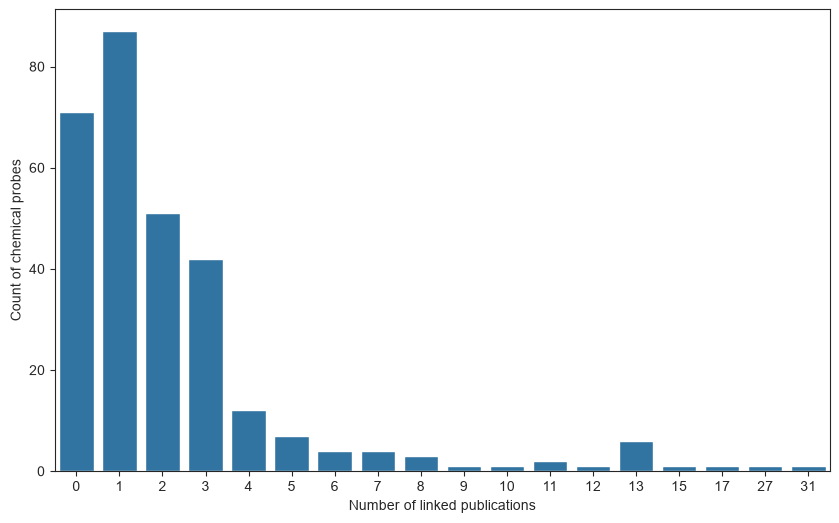

In [75]:

count_pubmeds = ner_triplets_ptpairs.groupby('probeId')[['probeYearPubmed','probeYearType']].nunique().reset_index()
print(count_pubmeds)
plt.figure(figsize=(10, 6)) # Optional: Adjust figure size
sns.countplot(data=count_pubmeds, x='probeYearPubmed')
plt.xlabel("Number of linked publications")
plt.ylabel("Count of chemical probes")
plt.savefig((FIGURES_DIR / 'supp_linked_publications.png'), dpi=400)

In [76]:

display(ner_triplets_ptpairs.probeId.nunique())

#cases of probe without date provided by probes&drugs
nodates_subset = ner_triplets_ptpairs[ner_triplets_ptpairs.probeYear.isna()]
display(nodates_subset.probe.unique())

#Type of publication
display(ner_triplets_ptpairs[['probeId','probeYearType']].drop_duplicates().probeYearType.value_counts())

direct_probeIds = ner_triplets_ptpairs[ner_triplets_ptpairs['probeYearType'] == 'direct']['probeId'].unique()
activity_based_probeIds = ner_triplets_ptpairs[ner_triplets_ptpairs['probeYearType'] == 'activity-based']['probeId'].unique()
print(len(set(direct_probeIds)))
print(len(set(activity_based_probeIds) - set(direct_probeIds)))

296

array(['Vepdegestrant', 'GIREDESTRANT', 'deucravacitinib', 'APREPITANT',
       'MRTX0902', 'romidepsin', 'MRTX1133', 'ERTUGLIFLOZIN', 'AZD9574',
       'BRIVARACETAM', 'GSK484', 'itacitinib', 'avacopan', 'emavusertib',
       'SIROLIMUS', 'Nedisertib', 'Remibrutinib', 'ervogastat', 'SGC0946',
       'TANZISERTIB', 'GSK2656157', 'PF-9363', 'PAMAPIMOD', 'FIBOFLAPON',
       'MD-265', 'TP-064', 'BAY-805', 'ROCILETINIB', 'MAVELERTINIB',
       'SELEXIPAG', 'NT-0796', 'Bavdegalutamide', 'MRIA9', 'GPLG3970',
       'Osunprotafib', 'suzetrigine', 'Firsocostat', 'Saruparib',
       'MEZIGDOMIDE', 'CA-170', 'DYR684', 'ELAGOLIX', 'MU1700', 'M4K2234',
       'CCT244747', 'PF-03882845', 'GSK-J1', 'BI-9321', 'AM-6494',
       'zidesamtinib', 'TH9619', 'BMS-986278', 'selgantolimod', 'L-Moses',
       'ACBI3', 'SGC3027', 'GSK864', 'BI 113823', 'Lirafugratinib',
       'EPZ-719', 'MK-3697', 'ICENTICAFTOR', 'Zasocitinib', 'GSK3484862',
       'SGC6870', 'BI-5521', 'JNJ-9350', 'UNC6934', 'MFH290',
    

probeYearType
direct            194
activity-based    120
Name: count, dtype: int64

194
33


#### Only direct link publications

In [77]:

# only considering direct publications
date_subset =ner_triplets_ptpairs[ner_triplets_ptpairs.probeYearType == 'direct'] #chnage to dated evidence dataset in case we need the OT dates
print(ner_triplets_ptpairs.probeId.nunique())
print(date_subset.probeId.nunique())
#filter out cases without dates
date_subset = date_subset[~date_subset.probeYear.isna()]
date_subset.probeYear = date_subset.probeYear.astype('int')

296
194


In [78]:

date_subset.date = pd.to_datetime(date_subset.date)

In [79]:

date_subset.columns

Index(['diseaseId', 'targetId', 'datasourceId', 'datatypeId', 'score',
       'evidenceCount', 'pmid', 'date', 'section', 'probeId', 'sentence',
       'probe', 'inchiKey', 'gene', 'allcurationYears', 'allpublicationYears',
       'allstudyYears', 'datedEvidenceStatus', 'name', 'therapeuticAreas',
       'drugId', 'maxClinicalStage', 'clinicalStageRank',
       'hasClinicalIndication', 'articleType', 'maxPhase', 'probe_data',
       'preferredTA', 'target-disease', 'probeYear', 'probeYearPubmed',
       'probeYearType'],
      dtype='object')

In [80]:

display(len(date_subset[['targetId','diseaseId','probeId']].drop_duplicates()))
date_subset['triplets'] = date_subset.diseaseId + '-' + date_subset.targetId + '-' + date_subset.probeId
date_subset['year'] = date_subset.date.dt.year.astype(int)


8879

In [81]:

date_subset.probeId.nunique()

192

In [82]:

display(date_subset[['triplets', 'pmid', 'probeYear', 'year', 'probeYearPubmed']].drop_duplicates().head())

,triplets,pmid,probeYear,year,probeYearPubmed
0,MONDO_0005059-ENSG00000005339-CHEMBL4097025,35836809,2017,2022,28892380.0
1,MONDO_0005059-ENSG00000005339-CHEMBL4282264,40830799,2017,2025,28953875.0
2,MONDO_0005059-ENSG00000005339-CHEMBL4282264,40830799,2018,2025,29244478.0
3,MONDO_0005059-ENSG00000005339-CHEMBL4282264,40830799,2018,2025,29804834.0
5,MONDO_0005059-ENSG00000005339-CHEMBL4282264,35402805,2017,2019,28953875.0


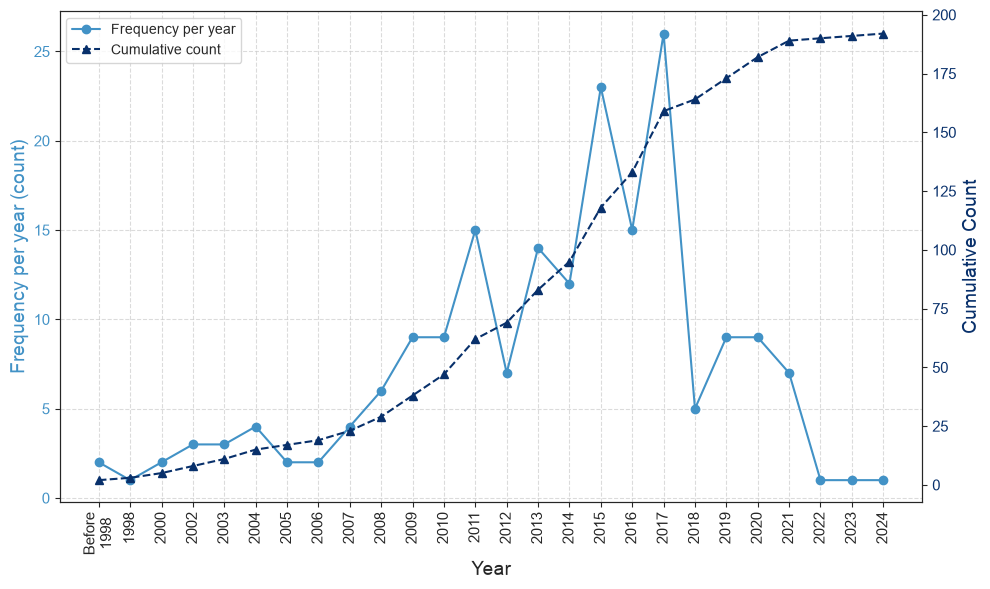

In [83]:
# --- 1. Process Data & Handle "Before 1998" ---
# Get unique probe counts per year
subset = date_subset[['probeId', 'probeYear']].drop_duplicates(subset=['probeId'], keep='first')
year_counts = subset['probeYear'].value_counts().sort_index()

# Split the data into "Before 1998" and "1998 onwards"
cutoff_year = 1998
pre_cutoff_counts = year_counts[year_counts.index < cutoff_year]
post_cutoff_counts = year_counts[year_counts.index >= cutoff_year]

# Aggregate the early years into one sum
pre_cutoff_sum = pre_cutoff_counts.sum()

# Create new lists for plotting
if pre_cutoff_sum > 0:
    # Combine the aggregated sum with the rest of the data
    plot_labels = ['Before\n1998'] + [str(y) for y in post_cutoff_counts.index]
    plot_freqs = [pre_cutoff_sum] + list(post_cutoff_counts.values)
else:
    # Fallback if no data exists before 1998
    plot_labels = [str(y) for y in post_cutoff_counts.index]
    plot_freqs = list(post_cutoff_counts.values)

# Calculate the cumulative sum on this NEW aggregated list
cumulative_values = np.cumsum(plot_freqs)

# Create an index for the x-axis (0, 1, 2, ...) to ensure equal spacing on the plot
x_positions = np.arange(len(plot_labels))


# --- 2. Create the Plot ---
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Frequency (Primary Axis)
color1 = '#4292c6'
ax1.set_xlabel('Year', fontsize=14)
ax1.set_ylabel('Frequency per year (count)', color=color1, fontsize=14)
# Note: We plot against 'x_positions', not the actual years
line1 = ax1.plot(x_positions, plot_freqs,
                 marker='o', linestyle='-', color=color1, label='Frequency per year')
ax1.tick_params(axis='y', labelcolor=color1, labelsize=11)
ax1.grid(True, linestyle='--', alpha=0.7)

# Plot Cumulative (Secondary Axis)
ax2 = ax1.twinx()
color2 = '#08306b'
ax2.set_ylabel('Cumulative Count', color=color2, fontsize=14)
line2 = ax2.plot(x_positions, cumulative_values,
                 marker='^', linestyle='--', color=color2, label='Cumulative count')
ax2.tick_params(axis='y', labelcolor=color2, labelsize=11)


# --- 3. Customize X-Axis to show Labels ---
# This is where we apply the text labels "Before 1998", "1998", etc.
ax1.set_xticks(x_positions)
ax1.set_xticklabels(plot_labels)
ax1.tick_params(axis='x', rotation=90, labelsize=11)

# Combined Legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

fig.tight_layout()
plt.savefig((FIGURES_DIR / 'probes_approval.png'), dpi=600)
plt.savefig((FIGURES_DIR / 'probes_approval.svg'), dpi=600)
plt.show()